# Thu thập dữ liệu & EDA: nhận diện khuôn mặt bị che khuất

**Đồ án CV nâng cao · Nhóm A/B/C · 21/10/2026**

Notebook này chứa toàn bộ phần thu thập dữ liệu và EDA. Mỗi phần đi theo một mạch: câu hỏi → cách đo → code → bảng/biểu đồ → diễn giải → hệ quả cho bước tiếp theo. Các file PDF đi kèm chỉ là tài liệu phụ.

## Câu hỏi cần trả lời

1. Thực tế tải được những nguồn nào? Số ảnh công bố, số URL, số bounding box và số ảnh đọc được khác nhau ra sao?
2. Mỗi nguồn có bao nhiêu người, mỗi người bao nhiêu ảnh, điều kiện nào được phủ đủ?
3. Có ảnh lỗi, nhãn mâu thuẫn, ảnh trùng, crop không chứa mặt hoặc ảnh đã crop sẵn không?
4. Độ phân giải, độ sáng, tương phản, độ nét khác nhau thế nào giữa ảnh tổng hợp và ảnh thật?
5. Các chỉ số chất lượng liên quan nhau ra sao? Có dùng được một ngưỡng chất lượng chung không?
6. Detector thất bại ở điều kiện nào? Mẫu số và độ bất định tính thế nào?
7. EDA hỗ trợ chọn preprocessing, model và protocol tới đâu; phần nào vẫn phải thử trên validation?

**Phạm vi:** thu thập dữ liệu, EDA và chạy thử B0. Chưa sửa nhãn, xóa ảnh, chia tập, preprocessing hàng loạt hay train B1/B2.

## 1. Môi trường và cách chạy lại

Chọn kernel Python 3.11 của `.venv` trong thư mục đồ án rồi `Restart Kernel → Run All`. Cell dưới tự tìm thư mục gốc của dự án nên không phụ thuộc ổ đĩa của máy.

- `RUN_DOWNLOAD=False`: dùng dữ liệu đã tải. Code tải vẫn nằm trong notebook; chỉ bật khi cần tải lại từ đầu (nhiều GB, một số link có thể đã chết).
- `PIXEL_CACHE_POLICY='auto'`: chỉ dùng cache khi danh sách ảnh và trạng thái file (kích thước, thời điểm sửa) còn khớp; đặt `'recompute'` để tính lại toàn bộ.
- `DETECTOR_CACHE_POLICY='auto'`: tương tự cho audit detector, gắn với đúng danh sách ảnh và cấu hình MTCNN.
- Mọi phép resize trong EDA chỉ tạo bản phân tích trong RAM, không ghi đè ảnh gốc.

In [1]:
from __future__ import annotations
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
import csv, hashlib, io, json, math, os, pickle, platform, random, re, shutil, sys, time
import urllib.request, urllib.error, zipfile
import importlib.metadata

import cv2
import imagehash
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image as PILImage, ImageOps
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Markdown, display
from scipy.stats import spearmanr, ks_2samp
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import torch
from facenet_pytorch import MTCNN, InceptionResnetV1

def find_project_root():
    for parent in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [parent, parent/'Đồ Án']:
            if (candidate/'ban_giao_nhom/eda/EDA_kham_pha_du_lieu.ipynb').exists():
                return candidate.resolve()
    raise FileNotFoundError('Mở notebook trong thư mục dự án có data/sources/rof/acquired_records.json')

ROOT = find_project_root()
EDA_SNAPSHOT = ROOT/'ban_giao_nhom/eda'
OUT_DIR = EDA_SNAPSHOT/'notebook_outputs'
FIG_DIR = OUT_DIR/'figures'
TABLE_DIR = OUT_DIR/'tables'
CACHE_DIR = OUT_DIR/'cache'
for folder in [OUT_DIR, FIG_DIR, TABLE_DIR, CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 20261021
RUN_DOWNLOAD = False
PIXEL_CACHE_POLICY = 'auto'   # 'auto' hoặc 'recompute'
DETECTOR_CACHE_POLICY = 'auto'
WORKERS = 8
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
cv2.setNumThreads(1)
sns.set_theme(style='whitegrid', font='Arial', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':170, 'axes.unicode_minus':False})
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
%matplotlib inline

environment = {'python':platform.python_version(), 'platform':platform.platform(),
               'torch':torch.__version__, 'cuda_runtime':torch.version.cuda,
               'device':DEVICE, 'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
               'seed':SEED}
display(pd.DataFrame([environment]).T.rename(columns={0:'giá trị'}))

H:\Nam tu\Hoc Ki 1\CV nang cao\Đồ Án\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,giá trị
python,3.11.9
platform,Windows-10-10.0.26300-SP0
torch,2.2.2+cu121
cuda_runtime,12.1
device,cuda:0
gpu,NVIDIA GeForce RTX 4060 Laptop GPU
seed,20261021


### Quy ước

- `identity` luôn được đọc dạng chuỗi để ID số của DigiFace không bị lẫn `int`/`str` khi ghép với tên người của MFR2/ROF.
- `source:identity` là khóa danh tính **trong từng nguồn**, chưa phải danh tính đã đối chiếu giữa các nguồn.
- Số liệu trong phần diễn giải được sinh trực tiếp từ biến bằng `display(Markdown(...))`, nên luôn khớp với lần chạy.
- Phần chữ dùng định dạng số Việt Nam (86.980 ảnh; 30,30%). Bảng pandas giữ định dạng mặc định của thư viện (86980; 0.3030; 1,243.2734).

In [2]:
SOURCE_COLOR = {'DigiFace':'#168C96','MFR2':'#E49332','ROF':'#7561A9','ROF_scene':'#C34C67'}
CONDITION_VI = {'clean':'rõ theo nhãn nguồn','masked':'khẩu trang',
                'sunglasses':'kính râm','synthetic_unannotated':'render, chưa gán nhãn che'}

def vn(x, digits=0):
    """Định dạng số kiểu Việt Nam: 86.980 và 30,30."""
    text = f'{x:,.{digits}f}'
    return text.replace(',', '_').replace('.', ',').replace('_', '.')

def pct(x, digits=2):
    return vn(100 * x, digits) + '%'

def save_table(frame, name):
    frame.to_csv(TABLE_DIR/f'{name}.csv', index=False, encoding='utf-8-sig')
    return frame

def show_table(frame, max_rows=25):
    display(frame.head(max_rows))
    if len(frame)>max_rows:
        display(Markdown(f'*Hiển thị {max_rows}/{vn(len(frame))} dòng; bảng đầy đủ nằm trong file CSV.*'))

def finish_figure(fig, name):
    fig.savefig(FIG_DIR/f'{name}.png', bbox_inches='tight')
    fig.savefig(FIG_DIR/f'{name}.svg', bbox_inches='tight')
    plt.show(); plt.close(fig)

def show_raw_grid(frame, name, cols=4, title='', label_cols=('source','identity','condition'), image_col='path'):
    frame=frame.reset_index(drop=True)
    rows=math.ceil(len(frame)/cols)
    fig,axes=plt.subplots(rows,cols,figsize=(cols*3.1,rows*3.0),squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax,(_,row) in zip(axes.flat,frame.iterrows()):
        with PILImage.open(ROOT/row[image_col]) as im:
            rgb=ImageOps.exif_transpose(im).convert('RGB')
            ax.imshow(rgb)
        labels=[str(row.get(k,'')) for k in label_cols]
        ax.set_title('\n'.join(labels),fontsize=9)
    fig.suptitle(title,fontsize=13,y=1.005)
    fig.tight_layout()
    finish_figure(fig,name)

def ecdf(ax, values, label, color=None, log=False):
    x=np.sort(pd.to_numeric(pd.Series(values),errors='coerce').dropna().to_numpy())
    if log: x=x[x>0]
    if not len(x): return
    # Một giá trị duy nhất vẫn phải hiện bước nhảy ECDF, không biến mất.
    ax.step(np.r_[x[0],x], np.r_[0,np.arange(1,len(x)+1)/len(x)], where='post',
            label=f'{label} (n={vn(len(x))})',color=color,lw=1.8)
    if log: ax.set_xscale('log')
    ax.set_ylim(0,1.02)

def file_sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(4*1024*1024), b''):h.update(block)
    return h.hexdigest()

## 2. Nguồn dữ liệu: chọn gì và thực tế tải được gì?

Kế hoạch ban đầu dùng CASIA-WebFace để fine-tune, nhưng link tải chỉ trả về trang báo vượt hạn mức (quota exceeded), không phải file dữ liệu. Vì vậy nguồn train hiện tại là **DigiFace-1M (phần P1, Microsoft)**; ROF và MFR2 là ảnh thật dùng để đánh giá.

| Nguồn | Vai trò | Hạn chế |
|---|---|---|
| DigiFace | Ảnh render có nhãn danh tính; subset cân bằng để fine-tune | Ảnh tổng hợp, đã có phụ kiện/vật che nên không mặc định là "ảnh rõ"; kích thước gốc 112×112 |
| ROF | Ảnh che thật (khẩu trang, kính râm) theo URL và annotation của tác giả | Nhiều link chết, một ảnh có thể có nhiều box; nhãn/crop chưa sạch nên bản crawl không phải benchmark chuẩn |
| MFR2 | Benchmark phụ dạng cặp ảnh, có nhãn khẩu trang | Nhỏ; ảnh đã xử lý về 160×160; nhiều cặp dùng lại cùng ảnh/người |
| Webcam nhóm | Kiểm tra ứng dụng thực tế | Chưa thu; cần tách phiên chụp và có người lạ (unknown) |

### Code tải dữ liệu

Hai cell tiếp theo không truy cập mạng khi `RUN_DOWNLOAD=False`. Trình tải DigiFace tải từng đoạn (HTTP Range), kiểm `Content-Range` và kiểm file ZIP sau khi ghép. Mỗi danh tính lấy 40 ảnh bằng seed cố định, giữ nguyên bytes gốc. SHA-256 tính trên máy là dấu vân tay cục bộ vì nhà phát hành không công bố checksum.

In [3]:
# Downloader DigiFace - constants và thuật toán tải/trích nguyên bản.
URL = 'https://facesyntheticspubwedata.z6.web.core.windows.net/wacv-2023/subjects_0-1999_72_imgs.zip'
SIZE = 2938553163
ARCHIVE = 'subjects_0-1999_72_imgs.zip'
def digest(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def download(target: Path, workers: int):
    if target.exists():
        if target.stat().st_size != SIZE:
            raise RuntimeError("Existing archive has an unexpected size; inspect it before retrying")
        return
    target.parent.mkdir(parents=True, exist_ok=True)
    parts = target.parent / "train_source_download_parts"
    parts.mkdir(exist_ok=True)
    blocksize = 64 * 1024 * 1024
    ranges = [(i, i * blocksize, min(SIZE, (i + 1) * blocksize) - 1)
              for i in range((SIZE + blocksize - 1) // blocksize)]
    # Preserve bytes from an earlier single-connection curl attempt.
    old = target.with_suffix(target.suffix + ".part")
    if old.exists() and old.stat().st_size <= SIZE and not any(parts.glob("*.part")):
        with old.open("rb") as source:
            i = 0
            while data := source.read(blocksize):
                (parts / f"{i:03d}.part").write_bytes(data)
                i += 1
        old.unlink()

    def get_range(item):
        i, start, end = item
        part = parts / f"{i:03d}.part"
        expected = end - start + 1
        for attempt in range(6):
            have = part.stat().st_size if part.exists() else 0
            if have == expected:
                return i, have
            if have > expected:
                raise RuntimeError(f"Oversized chunk {i}")
            request = urllib.request.Request(URL, headers={
                "Range": f"bytes={start + have}-{end}",
                "User-Agent": "CV-course-dataset-acquisition/1.0"})
            try:
                with urllib.request.urlopen(request, timeout=90) as response:
                    wanted = f"bytes {start + have}-{end}/{SIZE}"
                    if response.status != 206 or response.headers.get("Content-Range") != wanted:
                        raise RuntimeError(f"Unexpected range response: {response.status}, {response.headers}")
                    with part.open("ab") as f:
                        shutil.copyfileobj(response, f, length=1024 * 1024)
                if part.stat().st_size != expected:
                    raise OSError(f"Incomplete chunk {i}")
                return i, expected
            except (OSError, TimeoutError) as exc:
                if attempt == 5:
                    raise
                print(f"retry chunk {i}: {type(exc).__name__}", flush=True)
                time.sleep(min(30, 2 ** attempt))

    with ThreadPoolExecutor(max_workers=workers) as pool:
        jobs = [pool.submit(get_range, item) for item in ranges]
        for n, result in enumerate(as_completed(jobs), 1):
            i, count = result.result()
            done = sum(p.stat().st_size for p in parts.glob("*.part"))
            print(f"chunk {i} completed; {n}/{len(ranges)}; bytes {done}/{SIZE}", flush=True)
    combined = target.with_suffix(target.suffix + ".assembled")
    with combined.open("wb") as out:
        for i, _, _ in ranges:
            with (parts / f"{i:03d}.part").open("rb") as source:
                shutil.copyfileobj(source, out, length=4 * 1024 * 1024)
    if combined.stat().st_size != SIZE:
        raise RuntimeError("Assembled size mismatch")
    if not zipfile.is_zipfile(combined):
        raise RuntimeError("Not a ZIP archive")
    combined.rename(target)
    # Only exact chunk files generated by this downloader are removed.
    for i, _, _ in ranges:
        (parts / f"{i:03d}.part").unlink()
    parts.rmdir()

In [4]:
def inventory_extract(archive: Path, per_identity: int, seed: int):
    meta = ROOT / "data_acquisition"
    output = archive.parent / "images_eda"
    output.mkdir(exist_ok=True)
    identities = {}
    with zipfile.ZipFile(archive) as z:
        entries = z.infolist()
        for item in entries:
            if item.is_dir() or not item.filename.lower().endswith((".png", ".jpg", ".jpeg")):
                continue
            path = PurePosixPath(item.filename)
            if ".." in path.parts or path.is_absolute():
                raise RuntimeError("Unsafe archive path")
            # Official layout ends with subj_id/image.png; ignore optional wrapper directory.
            identity = path.parts[-2]
            identities.setdefault(identity, []).append(item)
        with (meta / "train_source_archive_inventory.csv").open("w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            w.writerow(["member", "bytes_uncompressed", "bytes_compressed", "crc32", "is_image"])
            for item in entries:
                w.writerow([item.filename, item.file_size, item.compress_size, f"{item.CRC:08x}",
                            int(item.filename.lower().endswith((".png", ".jpg", ".jpeg")))])
        with (meta / "train_source_identity_counts.csv").open("w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            w.writerow(["identity", "archive_images", "selected_eda_images"])
            for identity, members in sorted(identities.items()):
                w.writerow([identity, len(members), min(len(members), per_identity)])
        selected = []
        for identity, members in sorted(identities.items()):
            members = sorted(members, key=lambda x: x.filename)
            idseed = int(hashlib.sha256(f"{seed}/{identity}".encode()).hexdigest()[:16], 16)
            chosen = sorted(random.Random(idseed).sample(members, min(per_identity, len(members))),
                            key=lambda x: x.filename)
            for item in chosen:
                destination = output / identity / PurePosixPath(item.filename).name
                destination.parent.mkdir(exist_ok=True)
                # ZipExtFile checks the member CRC while reading. Preserve encoded bytes exactly.
                data = z.read(item)
                if destination.exists() and destination.read_bytes() != data:
                    raise RuntimeError(f"Existing extracted image differs: {destination}")
                if not destination.exists():
                    destination.write_bytes(data)
                selected.append([destination.relative_to(ROOT).as_posix(), identity, item.filename,
                                 len(data), hashlib.sha256(data).hexdigest()])
            if len(selected) % 4000 == 0:
                print(f"extracted {len(selected)} images", flush=True)
    with (meta / "train_source_selected_manifest.csv").open("w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["path", "identity", "archive_member", "bytes", "sha256"])
        w.writerows(selected)
    report = {
        "checked_at_utc": datetime.now(timezone.utc).isoformat(),
        "source": "Microsoft DigiFace-1M official part subjects_0-1999_72_imgs",
        "source_type": "synthetic rendered identities; not collected photographs",
        "url": URL, "expected_server_bytes": SIZE,
        "archive_bytes": archive.stat().st_size, "sha256_local": digest(archive),
        "publisher_checksum_available": False,
        "sha256_note": "Local integrity fingerprint, not publisher-authenticated checksum",
        "archive_members": len(entries), "archive_images": sum(map(len, identities.values())),
        "archive_identities": len(identities), "selected_images": len(selected),
        "selected_identities": len(identities), "per_identity_limit": per_identity, "seed": seed,
        "selection": "per identity deterministic random sample without replacement; no train/test split",
        "extraction": "original encoded image bytes; ZIP member CRC checked for selected files only",
        "unselected_crc_tested": False,
        "output": output.relative_to(ROOT).as_posix(),
        "license": "R-UDA v1.0; non-commercial computational research; retain attribution and downstream terms",
        "casia_status": "Official Drive GET returned quota exceeded HTML; not acquired",
    }
    (meta / "train_source_status.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
    print(json.dumps(report, indent=2), flush=True)

if RUN_DOWNLOAD:
    archive_path = ROOT/'data/raw/digiface'/ARCHIVE
    download(archive_path, workers=4)
    inventory_extract(archive_path, per_identity=40, seed=SEED)
else:
    print('Không tải lại DigiFace: dùng archive/ảnh gốc đã có, kiểm kê ở cell tiếp theo.')

Không tải lại DigiFace: dùng archive/ảnh gốc đã có, kiểm kê ở cell tiếp theo.


### ROF và MFR2: tải đúng từ nguồn của tác giả

ROF phát hành annotation gồm URL ảnh và bounding box. Pickle được đọc bằng bộ unpickler chỉ cho phép các kiểu NumPy cần thiết; không chạy script tải của repository. Ảnh gốc được lưu riêng; crop theo box của tác giả lưu vào `benchmark_views` để kiểm tra, **chưa phải preprocessing chính thức**. Một URL có thể chứa nhiều mặt, nên các crop từ cùng URL không chắc là cùng một người.

MFR2 được tải từ link trong repository MaskTheFace. Khi tải lại cần tuân thủ điều kiện sử dụng và ghi nguồn. Chỉ thử lại với lỗi tạm thời; không bỏ qua xác thực TLS và không gọi dồn khi bị chặn 429.

In [5]:
DATA = ROOT/'data'
HEADERS = {'User-Agent':'AcademicFaceDatasetAudit/1.0'}

class RestrictedUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        allowed = {('numpy.core.multiarray','scalar'): np.core.multiarray.scalar,
                   ('numpy.core.multiarray','_reconstruct'): np.core.multiarray._reconstruct,
                   ('numpy','ndarray'): np.ndarray, ('numpy','dtype'): np.dtype}
        if (module,name) in allowed: return allowed[(module,name)]
        raise pickle.UnpicklingError(f'Forbidden global: {module}.{name}')

def fetch(url, path, timeout=15, max_bytes=30_000_000):
    path = Path(path)
    if path.exists(): return {'status':'cached','bytes':path.stat().st_size}
    req=urllib.request.Request(url,headers=HEADERS)
    with urllib.request.urlopen(req,timeout=timeout) as r:
        content_type=r.headers.get('Content-Type','')
        chunks=[];total=0
        while True:
            b=r.read(131072)
            if not b:break
            total+=len(b)
            if total>max_bytes:raise ValueError('download_size_limit')
            chunks.append(b)
        payload=b''.join(chunks)
    path.parent.mkdir(parents=True,exist_ok=True)
    partial=path.with_suffix(path.suffix+'.part');partial.write_bytes(payload);partial.replace(path)
    return {'status':'downloaded','bytes':total,'content_type':content_type}

def safe_extract(z, dest):
    dest=dest.resolve();dest.mkdir(parents=True,exist_ok=True)
    for name in z.namelist():
        candidate=(dest/name).resolve()
        if not candidate.is_relative_to(dest):raise ValueError('unsafe_zip_member')
    z.extractall(dest)

def rof(workers):
    src=DATA/'sources'/'rof';src.mkdir(parents=True,exist_ok=True)
    archive=src/'repository.zip'
    fetch('https://codeload.github.com/ekremerakin/RealWorldOccludedFaces/zip/refs/heads/main',archive,60)
    with zipfile.ZipFile(archive) as z:safe_extract(z,src)
    records=[]
    for p in sorted(src.rglob('*.pkl')):
        annotations=RestrictedUnpickler(io.BytesIO(p.read_bytes())).load()
        identity=p.stem.replace('_wearing_mask','').replace('_wearing_sunglasses','')
        for key,a in annotations.items():
            for j,face in enumerate(a.get('faces',[])):
                records.append({'source':'ROF','identity':identity,'condition':p.parent.name,
                    'annotation_file':p.relative_to(ROOT).as_posix(),'annotation_key':str(key),
                    'face_index':j,'url':a['url'],'author_box_xy_width_height':[int(x) for x in face['box']]})
    (src/'annotation_records.json').write_text(json.dumps(records,ensure_ascii=False,indent=2),encoding='utf-8')
    urls=sorted({r['url'] for r in records})
    print(f'ROF {len(records)} annotated faces, {len(urls)} unique URLs',flush=True)
    logpath=src/'download_log.jsonl'
    results={}
    def task(url):
        key=hashlib.sha256(url.encode()).hexdigest();p=DATA/'raw'/'rof_originals'/(key+'.img')
        result={'url':url,'original_path':p.relative_to(ROOT).as_posix(),'url_id':key}
        t=time.time()
        try:
            result.update(fetch(url,p,timeout=10,max_bytes=30_000_000))
            with PILImage.open(p) as im:
                im.load();result.update(width=im.width,height=im.height,format=im.format)
            result['sha256']=hashlib.sha256(p.read_bytes()).hexdigest();result['ok']=True
        except Exception as e:result.update(ok=False,error=f'{type(e).__name__}: {str(e)[:240]}')
        result['seconds']=round(time.time()-t,3)
        return result
    with logpath.open('w',encoding='utf-8') as log,ThreadPoolExecutor(max_workers=workers) as pool:
        for i,result in enumerate(pool.map(task,urls),1):
            results[result['url']]=result;log.write(json.dumps(result,ensure_ascii=False)+'\n');log.flush()
            if i%100==0:print(f'ROF URLs {i}/{len(urls)} ok {sum(x["ok"] for x in results.values())}',flush=True)
    crop_rows=[]
    for i,r in enumerate(records):
        result=results[r['url']];row={**r,'download_ok':result['ok'],'original_path':result['original_path']}
        row['image_id']='ROF_'+hashlib.sha256((r['annotation_file']+'|'+r['annotation_key']+'|'+str(r['face_index'])).encode()).hexdigest()[:20]
        if result['ok']:
            try:
                with PILImage.open(ROOT/result['original_path']) as im:
                    im=im.convert('RGB');x,y,w,h=r['author_box_xy_width_height']
                    # Explicit clipping; unlike original script, include final row/column.
                    box=(max(0,x),max(0,y),min(im.width,x+w),min(im.height,y+h))
                    if box[2]<=box[0] or box[3]<=box[1]:raise ValueError('invalid_author_box')
                    p=DATA/'benchmark_views'/'rof'/r['condition']/r['identity']/(row['image_id']+'.png')
                    p.parent.mkdir(parents=True,exist_ok=True);im.crop(box).save(p)
                    row.update(path=p.relative_to(ROOT).as_posix(),crop_ok=True,clipped_box=list(box),
                        box_clipped=list(box)!=[x,y,x+w,y+h])
            except Exception as e:row.update(crop_ok=False,error=str(e))
        else:row.update(crop_ok=False,error=result.get('error'))
        crop_rows.append(row)
    (src/'acquired_records.json').write_text(json.dumps(crop_rows,ensure_ascii=False,indent=2),encoding='utf-8')
    print('ROF COMPLETE',len(crop_rows),'crops',sum(r['crop_ok'] for r in crop_rows),flush=True)

def mfr2():
    src=DATA/'sources'/'mfr2';src.mkdir(parents=True,exist_ok=True)
    for name in ['readme.md','datasets/download_links.txt','LICENSE']:
        fetch('https://raw.githubusercontent.com/aqeelanwar/MaskTheFace/master/'+name,src/Path(name).name)
    url='https://drive.usercontent.google.com/download?id=1ukk0n_srRqcsotK2MjlFPj7L0sXcR2fH&export=download&confirm=t'
    p=src/'mfr2.zip';info=fetch(url,p,60,500_000_000)
    if not zipfile.is_zipfile(p):raise ValueError('MFR2 response is not ZIP; inspect saved response')
    with zipfile.ZipFile(p) as z:safe_extract(z,DATA/'raw'/'mfr2')
    info.update(source_url=url,sha256=hashlib.sha256(p.read_bytes()).hexdigest())
    (src/'acquisition.json').write_text(json.dumps(info,indent=2),encoding='utf-8')
    print('MFR2 COMPLETE',info,flush=True)

if RUN_DOWNLOAD:
    mfr2()
    rof(workers=4)
else:
    print('Không crawl lại URL: giữ snapshot crawl để kết quả EDA có thể truy xuất.')

Không crawl lại URL: giữ snapshot crawl để kết quả EDA có thể truy xuất.


In [6]:
# Kiểm kê trực tiếp central directory của archive, không chỉ tin bảng tóm tắt cũ.
archive_path=ROOT/'data/raw/digiface'/ARCHIVE
with zipfile.ZipFile(archive_path) as z:
    archive_entries=[i for i in z.infolist() if not i.is_dir() and i.filename.lower().endswith('.png')]
archive_id_counts=pd.Series([PurePosixPath(i.filename).parts[-2] for i in archive_entries]).value_counts()
digiface_status=json.loads((ROOT/'data_acquisition/train_source_status.json').read_text())
rof_records=pd.DataFrame(json.loads((ROOT/'data/sources/rof/acquired_records.json').read_text(encoding='utf-8')))
rof_log=pd.DataFrame([json.loads(s) for s in (ROOT/'data/sources/rof/download_log.jsonl').read_text(encoding='utf-8').splitlines()])
mfr_base=ROOT/'data/raw/mfr2/mfr2'
source_inventory=pd.DataFrame([
    {'source':'DigiFace archive','unit':'encoded PNG','count':len(archive_entries),'identities':len(archive_id_counts)},
    {'source':'ROF annotations','unit':'face-box records','count':len(rof_records),'identities':rof_records.identity.nunique()},
    {'source':'ROF requested','unit':'unique URL','count':len(rof_log),'identities':np.nan},
    {'source':'ROF downloaded','unit':'decoded source image URL','count':int(rof_log.ok.sum()),'identities':np.nan},
    {'source':'ROF crop candidates','unit':'usable-to-decode crop','count':int(rof_records.crop_ok.sum()),'identities':rof_records[rof_records.crop_ok].identity.nunique()},
    {'source':'MFR2','unit':'PNG file','count':len(list(mfr_base.rglob('*.png'))),'identities':len([p for p in mfr_base.iterdir() if p.is_dir()])},
])
save_table(source_inventory,'02_source_inventory');show_table(source_inventory)
per_id_text=(f'đều có {archive_id_counts.min()} ảnh' if archive_id_counts.min()==archive_id_counts.max()
             else f'có {archive_id_counts.min()}–{archive_id_counts.max()} ảnh')
display(Markdown(f"""### Kết quả
- Archive DigiFace có **{vn(len(archive_entries))} ảnh / {vn(len(archive_id_counts))} danh tính**, mỗi danh tính {per_id_text}. Subset dùng cho EDA được kiểm ở phần 5.
- ROF có **{vn(len(rof_records))} bbox ứng viên**, nhưng chỉ **{vn(rof_log.ok.sum())}/{vn(len(rof_log))} URL** tải và đọc được. Bbox và URL là hai đơn vị khác nhau nên không cộng hay chia chéo.
- Annotation ROF có **{rof_records.identity.nunique()} nhãn**, khác con số 180 người trong bài báo. Cần đối chiếu phiên bản ở bước QA; đây chưa phải bằng chứng có thêm người hợp lệ.
- DigiFace giữ vai trò nguồn train; ROF/MFR2 chỉ dùng để đánh giá, không trộn vào train.
"""))

,source,unit,count,identities
0,DigiFace archive,encoded PNG,144000,"2,000.0000"
1,ROF annotations,face-box records,10137,183.0000
2,ROF requested,unique URL,9520,NaN
3,ROF downloaded,decoded source image URL,6296,NaN
4,ROF crop candidates,usable-to-decode crop,6711,182.0000
5,MFR2,PNG file,269,53.0000


### Kết quả
- Archive DigiFace có **144.000 ảnh / 2.000 danh tính**, mỗi danh tính đều có 72 ảnh. Subset dùng cho EDA được kiểm ở phần 5.
- ROF có **10.137 bbox ứng viên**, nhưng chỉ **6.296/9.520 URL** tải và đọc được. Bbox và URL là hai đơn vị khác nhau nên không cộng hay chia chéo.
- Annotation ROF có **183 nhãn**, khác con số 180 người trong bài báo. Cần đối chiếu phiên bản ở bước QA; đây chưa phải bằng chứng có thêm người hợp lệ.
- DigiFace giữ vai trò nguồn train; ROF/MFR2 chỉ dùng để đánh giá, không trộn vào train.


## 3. Link chết có làm lệch dữ liệu không?

Phần ảnh còn lại không nhất thiết là mẫu ngẫu nhiên: link của một số người hoặc điều kiện có thể chết nhiều hơn. Vì vậy cần báo tỷ lệ giữ lại theo **từng danh tính × điều kiện**, không chỉ một tỷ lệ chung. Bảng công bố của ROF (3.195 ảnh thường / 1.686 kính râm / 678 khẩu trang) đếm theo ảnh, còn annotation đếm theo bbox, nên không chia hai con số này cho nhau để ra "tỷ lệ tải được".

,annotated_faces,requested_urls,crop_ok_faces,identities_requested,identities_with_crop,candidate_face_retention
condition,,,,,,
masked,515,463,264,67,57,0.5126
neutral,6659,6342,4356,182,181,0.6542
sunglasses,2963,2720,2091,159,157,0.7057


,reason,URLs
0,HTTP_404,1800
1,URLError,477
2,HTTP_403,309
3,HTTP_400,276
4,HTTP_429,152
5,UnidentifiedImageError,67
6,HTTP_401,33
7,HTTP_410,25
8,TimeoutError,20
9,HTTP_503,14


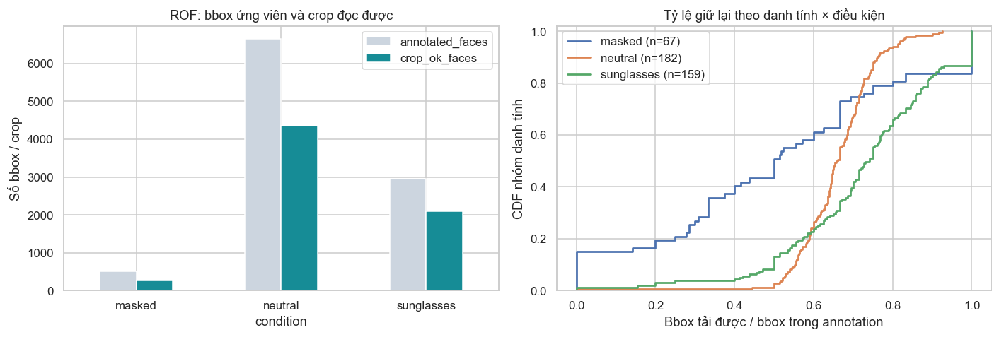

### Diễn giải
**13 nhóm danh tính × điều kiện không còn crop nào.** Nếu chỉ đọc thư mục ảnh tải thành công, các nhóm này sẽ biến mất mà không để lại dấu vết, nên manifest phải giữ cả bản ghi thất bại.

Lỗi chủ yếu là HTTP 404, lỗi kết nối (DNS/TLS) và 403; ngoài ra 152 URL bị chặn 429 (giới hạn tần suất). Một lượt thử lại có kiểm soát không khôi phục thêm ảnh nào. Đây là giới hạn của khâu thu thập, không liên quan tới model; chưa thể coi phần còn lại là đại diện cho toàn bộ ROF công bố.


In [7]:
attrition=rof_records.groupby('condition').agg(
    annotated_faces=('image_id','size'),requested_urls=('url','nunique'),
    crop_ok_faces=('crop_ok','sum'),identities_requested=('identity','nunique'))
attrition['identities_with_crop']=rof_records[rof_records.crop_ok].groupby('condition').identity.nunique()
attrition['candidate_face_retention']=attrition.crop_ok_faces/attrition.annotated_faces
save_table(attrition.reset_index(),'03_rof_attrition');display(attrition)

failure=rof_log[~rof_log.ok].copy()
failure['error_group']=failure.error.map(lambda x: 'HTTP_'+re.search(r'HTTP Error (\d+)',x).group(1)
                                       if 'HTTP Error' in x else x.split(':')[0])
failure_counts=failure.error_group.value_counts().rename_axis('reason').reset_index(name='URLs')
save_table(failure_counts,'03_download_errors');display(failure_counts)
by_person=rof_records.groupby(['identity','condition']).agg(requested=('image_id','size'),acquired=('crop_ok','sum')).reset_index()
by_person['retention']=by_person.acquired/by_person.requested
save_table(by_person,'03_identity_attrition')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
attrition[['annotated_faces','crop_ok_faces']].plot.bar(ax=axes[0],color=['#CCD5DF','#168C96'],rot=0)
axes[0].set(title='ROF: bbox ứng viên và crop đọc được',ylabel='Số bbox / crop')
for c,g in by_person.groupby('condition'):
    ecdf(axes[1],g.retention,c)
axes[1].set(title='Tỷ lệ giữ lại theo danh tính × điều kiện',xlabel='Bbox tải được / bbox trong annotation',ylabel='CDF nhóm danh tính')
axes[1].legend();fig.tight_layout();finish_figure(fig,'03_crawl_attrition')
n_429=int(failure.error_group.eq('HTTP_429').sum())
display(Markdown(f"""### Diễn giải
**{(by_person.acquired==0).sum()} nhóm danh tính × điều kiện không còn crop nào.** Nếu chỉ đọc thư mục ảnh tải thành công, các nhóm này sẽ biến mất mà không để lại dấu vết, nên manifest phải giữ cả bản ghi thất bại.

Lỗi chủ yếu là HTTP 404, lỗi kết nối (DNS/TLS) và 403; ngoài ra {vn(n_429)} URL bị chặn 429 (giới hạn tần suất). Một lượt thử lại có kiểm soát không khôi phục thêm ảnh nào. Đây là giới hạn của khâu thu thập, không liên quan tới model; chưa thể coi phần còn lại là đại diện cho toàn bộ ROF công bố.
"""))

## 4. Tạo manifest và đơn vị quan sát

Mỗi dòng manifest là một ảnh/crop, không phải một người. Manifest lưu nguồn, nhãn nguồn, điều kiện, đường dẫn, `original_id` và trạng thái chia tập. `session_id=unknown` được giữ nguyên, không suy phiên chụp từ tên file.

Hàm dưới duyệt thư mục và annotation để dựng manifest; các chỉ số pixel được tính trực tiếp trên ảnh ở phần 5.

In [8]:
def inventory():
    rows=[]
    # DigiFace: byte-preserved deterministic 40/identity subset, no resizing.
    for p in sorted((ROOT/'data/raw/digiface/images_eda').rglob('*')):
        if p.suffix.lower() not in ['.png','.jpg','.jpeg']:continue
        rows.append(dict(image_id='DF_'+hashlib.sha256(p.relative_to(ROOT).as_posix().encode()).hexdigest()[:20],
            source='DigiFace',identity=p.parent.name,condition='synthetic_unannotated',
            mask_type='unknown',path=p.relative_to(ROOT).as_posix(),role='fine_tune_candidate',
            label_status='source_label_unverified',session_id='unknown',split='unassigned'))
    base=ROOT/'data/raw/mfr2/mfr2'
    labels={}
    for line in (base/'mfr2_labels.txt').read_text(encoding='utf-8-sig').splitlines():
        if not line.strip():continue
        ident,idx,mask=[x.strip() for x in line.split(',')]
        labels[(ident,int(idx))]=mask
    for p in sorted(base.rglob('*.png')):
        ident=p.parent.name;idx=int(p.stem.rsplit('_',1)[1]);mask=labels.get((ident,idx),'unknown')
        rows.append(dict(image_id='MFR2_'+p.stem,source='MFR2',identity=ident,
            condition='clean' if mask=='no-mask' else ('unknown' if mask=='unknown' else 'masked'),
            mask_type=mask,path=p.relative_to(ROOT).as_posix(),role='external_evaluation',
            label_status='source_label_unverified',session_id='unknown',split='unassigned'))
    rp=ROOT/'data/sources/rof/acquired_records.json'
    if rp.exists():
        for r in json.loads(rp.read_text(encoding='utf-8')):
            if not r.get('crop_ok'):continue
            rows.append(dict(image_id=r['image_id'],source='ROF',identity=r['identity'],condition={'neutral':'clean'}.get(r['condition'],r['condition']),
                mask_type=r['condition'],path=r['path'],original_path=r['original_path'],
                role='external_evaluation_candidate',label_status='author_box_identity_requires_review',
                session_id='unknown',split='unassigned',source_url=r['url'],
                original_id=hashlib.sha256(r['url'].encode()).hexdigest(),annotation_key=r['annotation_key'],
                author_box=json.dumps(r['author_box_xy_width_height']),box_clipped=r['box_clipped']))
    df=pd.DataFrame(rows)
    if df.empty:raise ValueError('no images')
    if df.image_id.duplicated().any():raise ValueError('duplicate image ids')
    return df

In [9]:
inventory_df=inventory()
assert inventory_df.image_id.is_unique
assert inventory_df['split'].eq('unassigned').all()
save_table(inventory_df,'04_inventory')
display(inventory_df.head(5))
display(inventory_df.groupby('source').agg(images=('image_id','size'),identities=('identity','nunique')))
schema=pd.DataFrame([
    ['image_id / path','Khóa ảnh / đường dẫn tương đối','Dùng để truy ảnh, không là đặc trưng model'],
    ['source / identity','Nguồn và ID nguồn','Chưa xác minh alias giữa các nguồn'],
    ['condition / mask_type','Nhãn điều kiện từ nguồn','DigiFace chưa có nhãn clean/occluded'],
    ['original_id / source_url','Ảnh nguồn và URL','Nhóm crop/biến thể cùng cảnh để chống leakage'],
    ['session_id','Phiên thu','unknown với ảnh web/render, không tự điền'],
    ['split / role','Tập và vai trò','Chưa khóa split; nguồn đánh giá không dùng train'],
],columns=['field','meaning','caution'])
display(schema)

,image_id,source,identity,condition,mask_type,path,role,label_status,session_id,split,original_path,source_url,original_id,annotation_key,author_box,box_clipped
0,DF_03d4c195ac6c6541a89f,DigiFace,0,synthetic_unannotated,unknown,data/raw/digiface/images_eda/0/0.png,fine_tune_candidate,source_label_unverified,unknown,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
1,DF_a1b2fd56e9b3a25be1f0,DigiFace,0,synthetic_unannotated,unknown,data/raw/digiface/images_eda/0/1.png,fine_tune_candidate,source_label_unverified,unknown,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
2,DF_8389ca5693d0e60d7877,DigiFace,0,synthetic_unannotated,unknown,data/raw/digiface/images_eda/0/11.png,fine_tune_candidate,source_label_unverified,unknown,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
3,DF_0c6c9a3231b16b948c62,DigiFace,0,synthetic_unannotated,unknown,data/raw/digiface/images_eda/0/12.png,fine_tune_candidate,source_label_unverified,unknown,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
4,DF_bfc9de040d4c671b35ff,DigiFace,0,synthetic_unannotated,unknown,data/raw/digiface/images_eda/0/13.png,fine_tune_candidate,source_label_unverified,unknown,unassigned,NaN,NaN,NaN,NaN,NaN,NaN


,images,identities
source,,
DigiFace,80000,2000
MFR2,269,53
ROF,6711,182


,field,meaning,caution
0,image_id / path,Khóa ảnh / đường dẫn tương đối,"Dùng để truy ảnh, không là đặc trưng model"
1,source / identity,Nguồn và ID nguồn,Chưa xác minh alias giữa các nguồn
2,condition / mask_type,Nhãn điều kiện từ nguồn,DigiFace chưa có nhãn clean/occluded
3,original_id / source_url,Ảnh nguồn và URL,Nhóm crop/biến thể cùng cảnh để chống leakage
4,session_id,Phiên thu,"unknown với ảnh web/render, không tự điền"
5,split / role,Tập và vai trò,Chưa khóa split; nguồn đánh giá không dùng train


## 5. Kiểm tra pixel: ảnh có đọc được và có thông tin không?

### Cách đo

- Decode toàn bộ ảnh, ghi kích thước, mode, format, hướng EXIF. `read_ok` chỉ có nghĩa là **đọc được**, chưa nói gì về việc có mặt hay nhãn đúng.
- SHA-256 trên **bytes** tìm file giống hệt; SHA-256 trên **pixel RGB + kích thước** tìm ảnh cùng pixel dù khác metadata hoặc cách nén.
- pHash 64 bit dùng để tìm ứng viên gần trùng; phải xem bằng mắt, không tự gộp danh tính.
- Độ sáng, tương phản, phân vị p05/p95, tỷ lệ pixel quá tối/quá sáng, phương sai Laplacian, entropy, độ bão hòa và mật độ cạnh được đo trên bản resize 160×160. Đây là chỉ báo cho cả khung ảnh, nên bị ảnh hưởng bởi nền, khẩu trang và độ phân giải.
- Cache pixel gắn với danh sách ảnh, kích thước file, thời điểm sửa (`mtime_ns`) và phiên bản công thức. Nếu nghi dữ liệu bị sửa mà vẫn giữ nguyên kích thước và thời điểm sửa, đặt `'recompute'`.

In [10]:
def pixel_one(row):
    p=ROOT/row['path'];result={'image_id':row['image_id']}
    try:
        b=p.read_bytes();result.update(bytes=len(b),sha256=hashlib.sha256(b).hexdigest())
        with PILImage.open(io.BytesIO(b)) as im:
            im.load();result.update(width=im.width,height=im.height,mode=im.mode,format=im.format,
                exif_orientation=im.getexif().get(274,1))
            rgba=ImageOps.exif_transpose(im)
            has_alpha='A' in rgba.getbands() or 'transparency' in rgba.info
            alpha=np.asarray(rgba.convert('RGBA').getchannel('A')) if has_alpha else None
            result.update(has_alpha_channel=has_alpha,
                alpha_min=int(alpha.min()) if has_alpha else 255,
                alpha_max=int(alpha.max()) if has_alpha else 255,
                nonopaque_fraction=float((alpha<255).mean()) if has_alpha else 0.0)
            rgb=rgba.convert('RGB')
        arr=np.asarray(rgb)
        result['pixel_sha256']=hashlib.sha256(str(arr.shape).encode()+arr.tobytes()).hexdigest()
        result['phash64']=str(imagehash.phash(rgb,hash_size=8))
        # Standardized analysis resolution ONLY: never written as model input.
        analysis=rgb.resize((160,160),PILImage.Resampling.BILINEAR)
        a=np.asarray(analysis);g=cv2.cvtColor(a,cv2.COLOR_RGB2GRAY)
        hist=np.bincount(g.ravel(),minlength=256);pr=hist[hist>0]/g.size
        result.update(read_ok=True,aspect_ratio=rgb.width/rgb.height,min_side=min(rgb.size),
            brightness=float(g.mean()),contrast=float(g.std()),
            gray_p05=float(np.percentile(g,5)),gray_p95=float(np.percentile(g,95)),
            dark_fraction=float((g<16).mean()),bright_fraction=float((g>239).mean()),
            blur_laplacian_160=float(cv2.Laplacian(g,cv2.CV_64F).var()),
            entropy_bits=float(-(pr*np.log2(pr)).sum()),
            red_mean=float(a[:,:,0].mean()),green_mean=float(a[:,:,1].mean()),blue_mean=float(a[:,:,2].mean()),
            saturation_mean=float(cv2.cvtColor(a,cv2.COLOR_RGB2HSV)[:,:,1].mean()),
            edge_density=float((cv2.Canny(g,50,150)>0).mean()))
    except Exception as e:result.update(read_ok=False,read_error=f'{type(e).__name__}: {e}')
    return result

In [11]:
pixel_inventory=inventory_df.sort_values('image_id').copy()
file_state=[]
for row in pixel_inventory.itertuples():
    st=(ROOT/row.path).stat()
    file_state.append((row.image_id,row.path,st.st_size,st.st_mtime_ns))
PIXEL_SPEC='RGBA-alpha-audit|RGB-exif|bilinear160|phash64|laplacian64|v2'
pixel_fingerprint=hashlib.sha256(json.dumps([PIXEL_SPEC,file_state],ensure_ascii=False).encode()).hexdigest()
pixel_meta_path=CACHE_DIR/'pixel_meta.json';pixel_jsonl=CACHE_DIR/'pixel_audit.jsonl'
cache_match=(pixel_meta_path.exists() and json.loads(pixel_meta_path.read_text())['fingerprint']==pixel_fingerprint)
cached={}
if PIXEL_CACHE_POLICY=='auto' and cache_match and pixel_jsonl.exists():
    for line in pixel_jsonl.read_text(encoding='utf-8').splitlines():
        try:
            row=json.loads(line);cached[row['image_id']]=row
        except json.JSONDecodeError: pass
todo=[row for row in pixel_inventory.to_dict('records') if row['image_id'] not in cached]
write_mode='a' if cache_match and PIXEL_CACHE_POLICY=='auto' else 'w'
pixel_meta_path.write_text(json.dumps({'fingerprint':pixel_fingerprint,'spec':PIXEL_SPEC,'completed':False}),encoding='utf-8')
started=time.perf_counter()
with pixel_jsonl.open(write_mode,encoding='utf-8') as stream, ThreadPoolExecutor(max_workers=WORKERS) as pool:
    for i,row in enumerate(pool.map(pixel_one,todo),1):
        cached[row['image_id']]=row;stream.write(json.dumps(row,ensure_ascii=False)+'\n')
        if i%10000==0:
            stream.flush();print(f'Đã quét {i:,}/{len(todo):,} ảnh; {time.perf_counter()-started:.1f}s',flush=True)
pixel_meta={'fingerprint':pixel_fingerprint,'spec':PIXEL_SPEC,'images':len(pixel_inventory),
            'cached_before_run':len(pixel_inventory)-len(todo),'newly_computed':len(todo),
            'elapsed_seconds':time.perf_counter()-started,'seed':SEED,'completed':True}
pixel_meta_path.write_text(json.dumps(pixel_meta,indent=2),encoding='utf-8')
pixels=pd.DataFrame([cached[x] for x in inventory_df.image_id])
df=inventory_df.merge(pixels,on='image_id',validate='one_to_one')
df['identity']=df.identity.astype(str)
df['canonical_identity']=df.source+':'+df.identity
save_table(df,'05_manifest_pixel')
display(pd.DataFrame([pixel_meta]).drop(columns='fingerprint'))
display(df.groupby('source').agg(total=('image_id','size'),readable=('read_ok','sum')))
display(Markdown(f"""### Kết quả
Đã kiểm **{vn(len(df))} ảnh**: đọc được **{vn(df.read_ok.sum())}**, lỗi **{vn((~df.read_ok).sum())}**. Đây mới là bước "đọc được file"; việc có mặt, đúng người, đúng điều kiện được kiểm ở các phần sau.
"""))

,spec,images,cached_before_run,newly_computed,elapsed_seconds,seed,completed
0,RGBA-alpha-audit|RGB-exif|bilinear160|phash64|laplacian64|v2,86980,86980,0,0.0003,20261021,True


,total,readable
source,,
DigiFace,80000,80000
MFR2,269,269
ROF,6711,6711


### Kết quả
Đã kiểm **86.980 ảnh**: đọc được **86.980**, lỗi **0**. Đây mới là bước "đọc được file"; việc có mặt, đúng người, đúng điều kiện được kiểm ở các phần sau.


near_constant_images
source condition                      
ROF    clean                        17
       masked                        1

**Toàn bộ 80.000 ảnh DigiFace khớp SHA-256 với manifest trích từ archive.** Có **18 ảnh gần như một màu** (contrast < 1 và p95 − p05 ≤ 2 mức xám). Cần xem ảnh trước khi kết luận đây là ảnh giữ chỗ (placeholder).


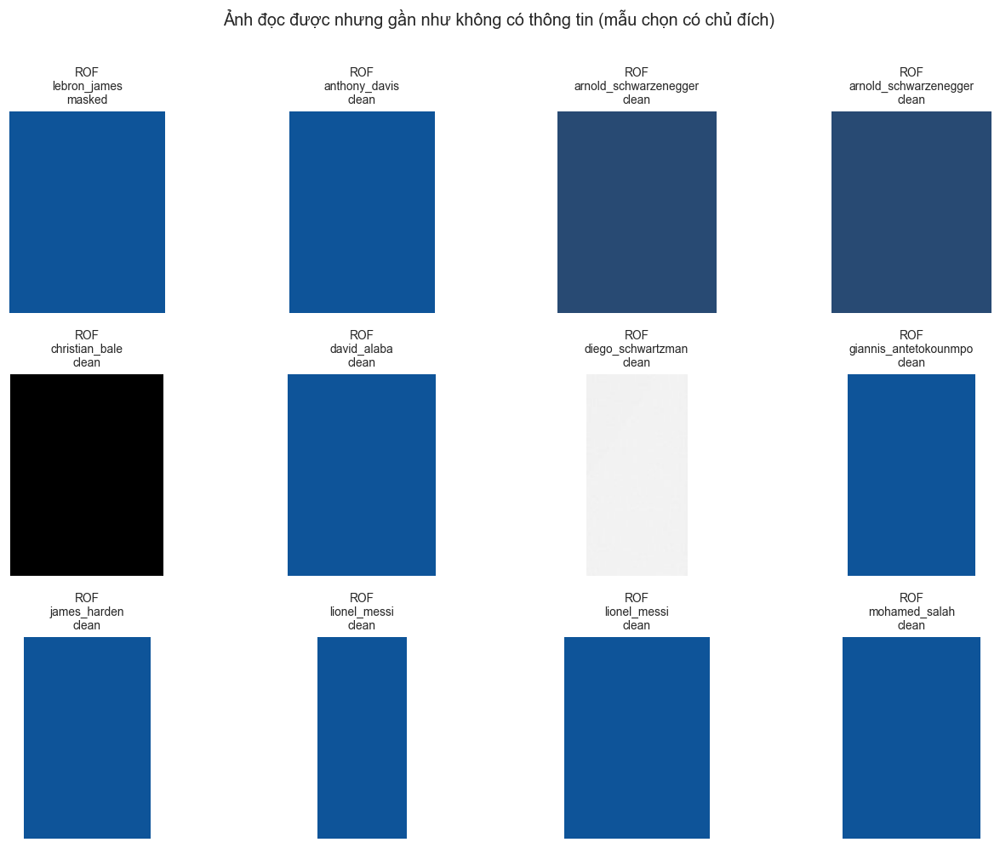

,source,mode,format,exif_orientation,images,alpha_images,images_with_transparency,minimum_alpha
0,DigiFace,RGBA,PNG,1,80000,80000,0,255
1,MFR2,RGB,PNG,1,269,0,0,255
2,ROF,RGB,PNG,1,6711,2,0,255


### Mode, kênh alpha, EXIF → quy ước đầu vào
DigiFace lưu RGBA, MFR2/ROF lưu RGB. Trên toàn bộ **86.980 ảnh** có **0 ảnh có alpha < 255**. Kênh alpha vì vậy luôn đục hoàn toàn: với dữ liệu hiện tại, chuyển sang RGB bằng cách bỏ kênh alpha là an toàn; nguồn mới phải kiểm lại.

EXIF được xử lý bằng `exif_transpose` trước khi đo và inference. Encoder nhận RGB 3 kênh theo chuẩn hóa của model pretrained; đảo BGR/RGB hoặc giữ 4 kênh sẽ làm sai đầu vào. Ảnh RGBA gốc vẫn giữ nguyên trên đĩa.


In [12]:
# Đối chiếu raw DigiFace với bytes đã trích từ archive.
selected=pd.read_csv(ROOT/'data_acquisition/train_source_selected_manifest.csv',dtype={'identity':str})
crosscheck=df[df.source=='DigiFace'][['path','sha256']].merge(
    selected[['path','sha256']],on='path',suffixes=('_current','_archive'),how='outer',indicator=True,validate='one_to_one')
assert crosscheck['_merge'].eq('both').all()
assert crosscheck.sha256_current.eq(crosscheck.sha256_archive).all()
constant=df[df.read_ok & (df.contrast<1) & ((df.gray_p95-df.gray_p05)<=2)].copy()
save_table(constant,'05_near_constant_review')
display(constant.groupby(['source','condition']).size().rename('near_constant_images').to_frame())
display(Markdown(f"""**Toàn bộ {vn(len(selected))} ảnh DigiFace khớp SHA-256 với manifest trích từ archive.** Có **{len(constant)} ảnh gần như một màu** (contrast < 1 và p95 − p05 ≤ 2 mức xám). Cần xem ảnh trước khi kết luận đây là ảnh giữ chỗ (placeholder).
"""))
show_raw_grid(constant.head(12),'05_near_constant_examples',title='Ảnh đọc được nhưng gần như không có thông tin (mẫu chọn có chủ đích)')

# Native encoding is distinct from the 3-channel tensor expected by the encoder.
encoding_summary=df[df.read_ok].groupby(['source','mode','format','exif_orientation']).agg(
    images=('image_id','size'),alpha_images=('has_alpha_channel','sum'),
    images_with_transparency=('nonopaque_fraction',lambda x:int(x.gt(0).sum())),
    minimum_alpha=('alpha_min','min')).reset_index()
save_table(encoding_summary,'05_encoding_alpha');display(encoding_summary)
nonopaque=int(df.nonopaque_fraction.gt(0).sum())
alpha_note=('Kênh alpha vì vậy luôn đục hoàn toàn: với dữ liệu hiện tại, chuyển sang RGB bằng cách bỏ kênh alpha là an toàn; nguồn mới phải kiểm lại.'
            if nonopaque==0 else 'Có ảnh trong suốt một phần nên phải ghép nền (compositing) trước khi chuyển sang RGB.')
display(Markdown(f"""### Mode, kênh alpha, EXIF → quy ước đầu vào
DigiFace lưu RGBA, MFR2/ROF lưu RGB. Trên toàn bộ **{vn(len(df))} ảnh** có **{vn(nonopaque)} ảnh có alpha < 255**. {alpha_note}

EXIF được xử lý bằng `exif_transpose` trước khi đo và inference. Encoder nhận RGB 3 kênh theo chuẩn hóa của model pretrained; đảo BGR/RGB hoặc giữ 4 kênh sẽ làm sai đầu vào. Ảnh RGBA gốc vẫn giữ nguyên trên đĩa.
"""))


## 6. Metadata thiếu: thiếu thật hay không áp dụng?

Ảnh web không có thông tin phiên chụp; ảnh render chưa gán nhãn che thì không được điền `clean`; `original_id` không áp dụng cho mọi nguồn. Vì vậy cần tách "thiếu do cấu trúc nguồn" với lỗi thu thập. Không suy đoán tuổi, giới tính, sắc tộc từ khuôn mặt và không suy tỷ lệ che từ điểm detector.

Trong bảng, `synthetic_unannotated` được tính là **chưa có nhãn che**, dù ô `condition` có giá trị.

,source,field,n,missing_or_unknown,fraction
0,DigiFace,session_id,80000,80000,1.0000
1,DigiFace,condition,80000,80000,1.0000
2,DigiFace,original_id,80000,80000,1.0000
3,DigiFace,source_url,80000,80000,1.0000
4,DigiFace,author_box,80000,80000,1.0000
5,MFR2,session_id,269,269,1.0000
6,MFR2,condition,269,0,0.0000
7,MFR2,original_id,269,269,1.0000
8,MFR2,source_url,269,269,1.0000
9,MFR2,author_box,269,269,1.0000


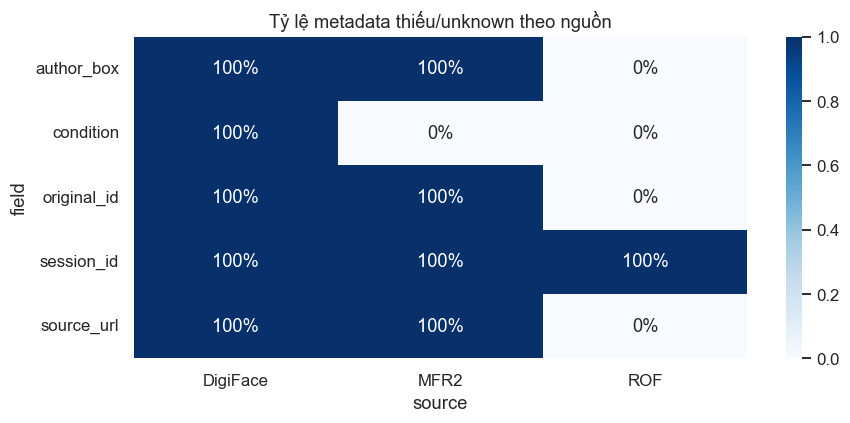

**Quyết định:** giữ giá trị unknown và ghi vào data card. Metadata hiện có chưa đủ để kiểm rò rỉ theo phiên chụp hay công bằng giữa các nhóm nhân khẩu. Khi thu webcam phải ghi `session_id` trước khi chia tập.

In [13]:
missing_rows=[]
for source,g in df.groupby('source'):
    for col in ['session_id','condition','original_id','source_url','author_box']:
        if col not in g: continue
        missing=g[col].isna()|g[col].astype(str).str.lower().isin(['unknown','nan','none',''])
        # synthetic_unannotated describes source, not an observed occlusion label.
        if col=='condition':missing=missing|g[col].eq('synthetic_unannotated')
        missing_rows.append({'source':source,'field':col,'n':len(g),'missing_or_unknown':int(missing.sum()),'fraction':missing.mean()})
missing_df=save_table(pd.DataFrame(missing_rows),'06_missing_metadata')
display(missing_df)
fig,ax=plt.subplots(figsize=(9,3.8))
pivot=missing_df.pivot(index='field',columns='source',values='fraction')
sns.heatmap(pivot,annot=True,fmt='.0%',cmap='Blues',vmin=0,vmax=1,ax=ax)
ax.set_title('Tỷ lệ metadata thiếu/unknown theo nguồn')
finish_figure(fig,'06_missing_metadata')
display(Markdown('**Quyết định:** giữ giá trị unknown và ghi vào data card. Metadata hiện có chưa đủ để kiểm rò rỉ theo phiên chụp hay công bằng giữa các nhóm nhân khẩu. Khi thu webcam phải ghi `session_id` trước khi chia tập.'))

## 7. Số ảnh mỗi danh tính và độ phủ điều kiện

Trong bài toán nhận diện, mỗi "lớp" là một danh tính. Nguồn train cần đủ biến thiên trong từng người; nguồn đánh giá cần ảnh gallery và ảnh query khác nhau. Có nhiều ảnh cũng không bù được việc chỉ có ít người đeo khẩu trang.

Bảng dưới đếm cả số ảnh và số **danh tính có ít nhất một ảnh** ở mỗi điều kiện. DigiFace có đúng 40 ảnh/người do cách lấy mẫu, không phải phân bố tự nhiên.

,images,identities,images_per_id_min,images_per_id_median,images_per_id_max,IDs_lt5
source,,,,,,
DigiFace,80000,2000,40,40.0000,40,0
MFR2,269,53,2,5.0000,10,19
ROF,6711,182,2,30.0000,95,1


,source,condition,images,identities
0,DigiFace,synthetic_unannotated,80000,2000
1,MFR2,clean,98,53
2,MFR2,masked,171,53
3,ROF,clean,4356,181
4,ROF,masked,264,57
5,ROF,sunglasses,2091,157


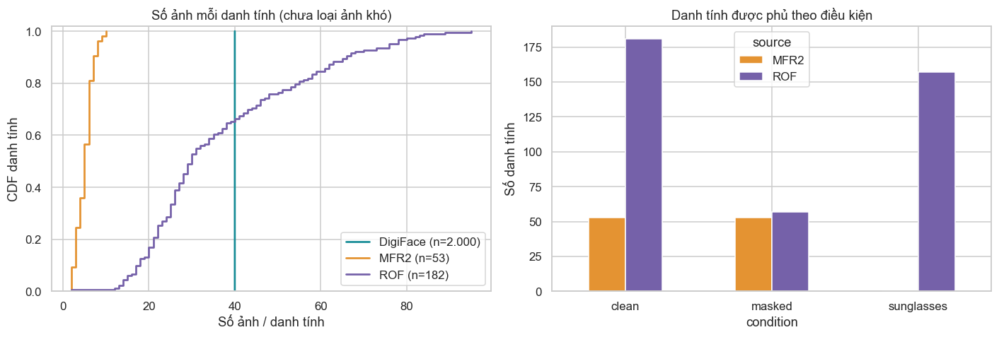

### Diễn giải cho thiết kế thí nghiệm
- DigiFace có **2.000 danh tính × 40 ảnh** trong subset. Sự cân bằng này thuận lợi cho so sánh B1/B2 nhưng không có nghĩa là nhãn che đã sạch.
- MFR2 có **19 người có dưới 5 ảnh**, nên không thể áp quy tắc đăng ký 5–10 ảnh rõ/người (dự kiến cho webcam) cho mọi người trong MFR2.
- Không báo một con số gộp chung, vì 80.000 ảnh render sẽ lấn át ảnh thật. Kết quả cần tách theo nguồn và điều kiện; tính theo ảnh (micro) và khi phù hợp thì theo danh tính (macro).


In [14]:
valid=df[df.read_ok].copy()
identity_counts=valid.groupby(['source','identity']).size().rename('images').reset_index()
source_summary=valid.groupby('source').agg(images=('image_id','size'),identities=('identity','nunique'))
for stat in ['min','median','max']:
    source_summary[f'images_per_id_{stat}']=identity_counts.groupby('source').images.agg(stat)
source_summary['IDs_lt5']=identity_counts[identity_counts.images<5].groupby('source').size().reindex(source_summary.index,fill_value=0)
coverage=valid.groupby(['source','condition']).agg(images=('image_id','size'),identities=('identity','nunique')).reset_index()
save_table(source_summary.reset_index(),'07_source_summary');save_table(coverage,'07_condition_coverage')
display(source_summary);display(coverage)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for source,g in identity_counts.groupby('source'):
    ecdf(axes[0],g.images,source,SOURCE_COLOR[source])
axes[0].set(xlabel='Số ảnh / danh tính',ylabel='CDF danh tính',title='Số ảnh mỗi danh tính (chưa loại ảnh khó)')
axes[0].legend()
cov=coverage[coverage.source!='DigiFace'].pivot(index='condition',columns='source',values='identities')
cov.plot.bar(ax=axes[1],rot=0,color=[SOURCE_COLOR[x] for x in cov.columns])
axes[1].set(title='Danh tính được phủ theo điều kiện',ylabel='Số danh tính')
fig.tight_layout();finish_figure(fig,'07_identity_and_coverage')
display(Markdown(f"""### Diễn giải cho thiết kế thí nghiệm
- DigiFace có **{vn(source_summary.loc['DigiFace','identities'])} danh tính × {int(source_summary.loc['DigiFace','images_per_id_min'])} ảnh** trong subset. Sự cân bằng này thuận lợi cho so sánh B1/B2 nhưng không có nghĩa là nhãn che đã sạch.
- MFR2 có **{vn(source_summary.loc['MFR2','IDs_lt5'])} người có dưới 5 ảnh**, nên không thể áp quy tắc đăng ký 5–10 ảnh rõ/người (dự kiến cho webcam) cho mọi người trong MFR2.
- Không báo một con số gộp chung, vì {vn(source_summary.loc['DigiFace','images'])} ảnh render sẽ lấn át ảnh thật. Kết quả cần tách theo nguồn và điều kiện; tính theo ảnh (micro) và khi phù hợp thì theo danh tính (macro).
"""))

### Có đủ ảnh để lập gallery ảnh rõ → query ảnh che không?

Bảng dưới chỉ kiểm tính khả thi dựa trên **nhãn của nguồn**, chưa tạo split hay chọn gallery. Nhãn `clean` của ROF/MFR2 vẫn cần qua QA, và kính cận trong suốt không tính là `sunglasses`. Gallery không được chứa chính ảnh query hoặc ảnh gần trùng với nó.

In [15]:
feasibility=[]
for source,g in valid[valid.source!='DigiFace'].groupby('source'):
    pivot=g.groupby(['identity','condition']).size().unstack(fill_value=0)
    for identity,row in pivot.iterrows():
        clean=int(row.get('clean',0));mask=int(row.get('masked',0));sun=int(row.get('sunglasses',0))
        feasibility.append({'source':source,'identity':identity,'clean':clean,'masked':mask,'sunglasses':sun,
                            'clean1_mask1':clean>=1 and mask>=1,'clean5_mask1':clean>=5 and mask>=1,
                            'all_three':clean>0 and mask>0 and sun>0})
feasibility=pd.DataFrame(feasibility)
save_table(feasibility,'07_gallery_query_feasibility')
display(feasibility.groupby('source')[['clean1_mask1','clean5_mask1','all_three']].sum())
display(Markdown('**Quyết định:** MFR2 giữ protocol cặp riêng. Với ROF, báo thêm kết quả trên cùng nhóm người có cả ảnh rõ và ảnh che, để chênh lệch không bị lẫn với khác biệt giữa các nhóm người.'))

,clean1_mask1,clean5_mask1,all_three
source,,,
MFR2,53,0,0
ROF,57,57,41


**Quyết định:** MFR2 giữ protocol cặp riêng. Với ROF, báo thêm kết quả trên cùng nhóm người có cả ảnh rõ và ảnh che, để chênh lệch không bị lẫn với khác biệt giữa các nhóm người.

## 8. Độ phân giải, tỷ lệ khung và ảnh đã crop sẵn

Cần phân biệt ba loại kích thước:

1. Kích thước file gốc hoặc crop của nguồn.
2. Kích thước bbox mặt mà detector tìm thấy trong file đó.
3. Kích thước tensor đầu vào encoder (160×160).

MFR2 đã được xử lý về 160×160, DigiFace gốc là 112×112; cả hai đều khác ảnh webcam toàn cảnh. Phóng 112 → 160 chỉ là nội suy, không tạo thêm chi tiết. Nếu resize mọi ảnh thành hình vuông trước khi xem tỷ lệ khung thì sẽ không thấy được các crop bị méo.

,source,condition,n,min_side_p05,min_side_median,min_side_p95,side_lt20,side_lt80,side_lt160,aspect_p01,aspect_p99
0,DigiFace,synthetic_unannotated,80000,112.0000,112.0000,112.0000,0,0,80000,1.0000,1.0000
1,MFR2,clean,98,160.0000,160.0000,160.0000,0,0,0,1.0000,1.0000
2,MFR2,masked,171,160.0000,160.0000,160.0000,0,0,0,1.0000,1.0000
3,ROF,clean,4356,35.0000,132.0000,518.0000,9,1233,2537,0.6197,0.8982
4,ROF,masked,264,37.0000,137.0000,434.0000,0,69,152,0.6513,0.9555
5,ROF,sunglasses,2091,43.0000,137.0000,461.5000,5,462,1200,0.6317,0.9278


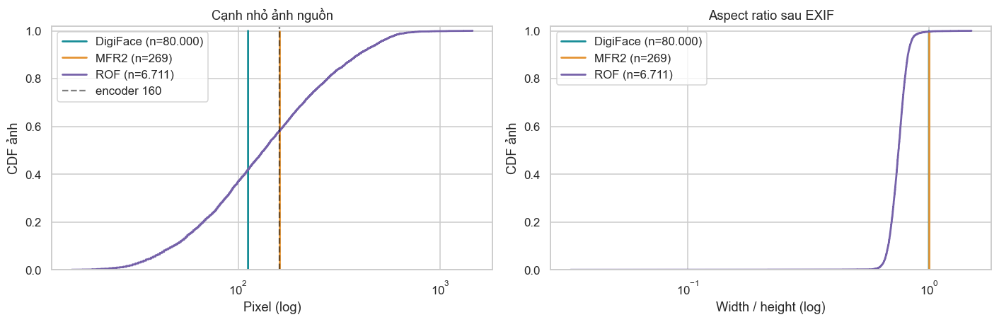

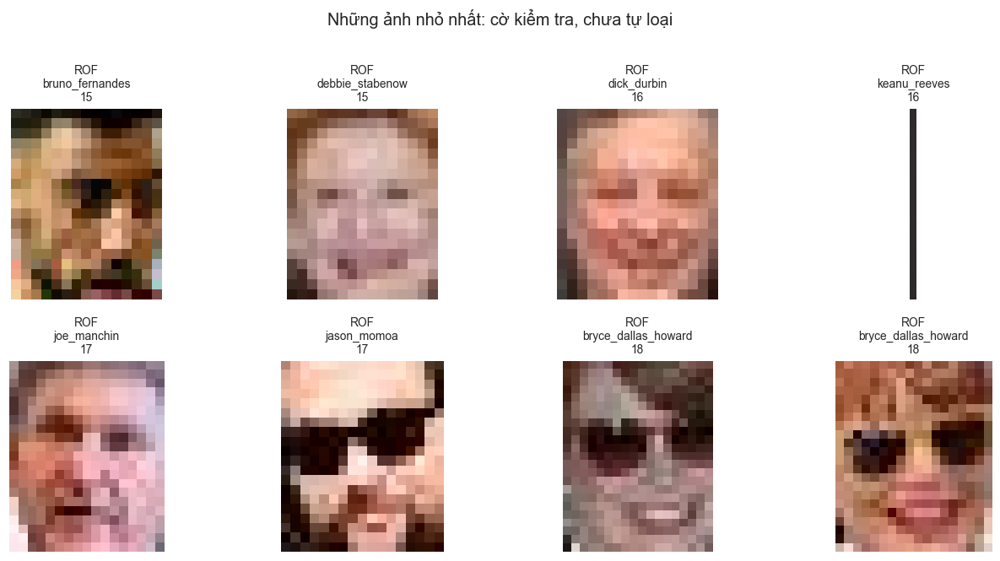

### Diễn giải và hệ quả cho preprocessing
**14 ảnh** có cạnh nhỏ dưới 20 px; **83.889/86.980 ảnh** có cạnh nhỏ dưới 160 px. Tỷ lệ này chủ yếu do ảnh 112×112 của DigiFace, nên không thể đặt ngưỡng 160 px để loại ảnh nhỏ.

Hướng xử lý: giữ kích thước gốc trong manifest, xem lại các crop quá nhỏ hoặc méo, tách ảnh đã crop sẵn với ảnh toàn cảnh, rồi thử chính sách xử lý trên một tập nhỏ. Chính sách cuối phải giống nhau cho B0/B1/B2; histogram chưa đủ để nói cách crop/resize nào tốt nhất.


In [16]:
resolution_rows=[]
for (source,condition),g in valid.groupby(['source','condition']):
    resolution_rows.append({'source':source,'condition':condition,'n':len(g),
                           'min_side_p05':g.min_side.quantile(.05),'min_side_median':g.min_side.median(),
                           'min_side_p95':g.min_side.quantile(.95),'side_lt20':int((g.min_side<20).sum()),
                           'side_lt80':int((g.min_side<80).sum()),'side_lt160':int((g.min_side<160).sum()),
                           'aspect_p01':g.aspect_ratio.quantile(.01),'aspect_p99':g.aspect_ratio.quantile(.99)})
resolution=pd.DataFrame(resolution_rows);save_table(resolution,'08_resolution');display(resolution)
fig,axes=plt.subplots(1,2,figsize=(13,4.3))
for source,g in valid.groupby('source'):
    ecdf(axes[0],g.min_side,source,SOURCE_COLOR[source],log=True)
    ecdf(axes[1],g.aspect_ratio,source,SOURCE_COLOR[source],log=True)
axes[0].axvline(160,color='black',ls='--',alpha=.5,label='encoder 160')
axes[0].set(title='Cạnh nhỏ ảnh nguồn',xlabel='Pixel (log)',ylabel='CDF ảnh');axes[0].legend()
axes[1].set(title='Aspect ratio sau EXIF',xlabel='Width / height (log)',ylabel='CDF ảnh');axes[1].legend()
fig.tight_layout();finish_figure(fig,'08_resolution_aspect')
small=valid.nsmallest(8,'min_side')
show_raw_grid(small,'08_smallest_examples',title='Những ảnh nhỏ nhất: cờ kiểm tra, chưa tự loại',label_cols=('source','identity','min_side'))
display(Markdown(f"""### Diễn giải và hệ quả cho preprocessing
**{vn((valid.min_side<20).sum())} ảnh** có cạnh nhỏ dưới 20 px; **{vn((valid.min_side<160).sum())}/{vn(len(valid))} ảnh** có cạnh nhỏ dưới 160 px. Tỷ lệ này chủ yếu do ảnh 112×112 của DigiFace, nên không thể đặt ngưỡng 160 px để loại ảnh nhỏ.

Hướng xử lý: giữ kích thước gốc trong manifest, xem lại các crop quá nhỏ hoặc méo, tách ảnh đã crop sẵn với ảnh toàn cảnh, rồi thử chính sách xử lý trên một tập nhỏ. Chính sách cuối phải giống nhau cho B0/B1/B2; histogram chưa đủ để nói cách crop/resize nào tốt nhất.
"""))

## 9. Độ sáng, tương phản, cháy sáng: có nên cân bằng histogram không?

Độ sáng là trung bình mức xám, tương phản là độ lệch chuẩn; cả hai đo trên toàn khung, gồm cả nền và vùng bị che. Tỷ lệ pixel < 16 hoặc > 239 chỉ là chỉ báo quá tối/cháy sáng, không phải nhãn phơi sáng chuẩn.

ECDF được vẽ **riêng cho từng nguồn**, nên so được hình dạng phân bố dù số ảnh giữa các nguồn chênh nhau rất nhiều.

,source,condition,metric,n,p01,p05,p25,p50,p75,p95,p99
0,DigiFace,synthetic_unannotated,brightness,80000,22.6945,37.0812,62.6085,82.8882,104.4189,136.9764,158.4086
1,DigiFace,synthetic_unannotated,contrast,80000,16.5746,23.3042,33.6904,42.3953,52.1829,68.8410,81.9656
8,MFR2,clean,brightness,98,64.5246,78.8428,103.1809,125.5661,142.8570,165.6019,172.4448
9,MFR2,clean,contrast,98,32.1305,39.3707,46.1297,53.4547,62.3601,75.8310,79.7061
16,MFR2,masked,brightness,171,61.9698,71.0399,96.6885,118.5897,135.2514,160.4827,194.3069
17,MFR2,masked,contrast,171,37.8012,44.5715,52.7948,59.6347,67.0999,78.6623,83.9929
24,ROF,clean,brightness,4356,58.0628,78.7369,108.6491,128.4253,145.9592,166.8939,183.3262
25,ROF,clean,contrast,4356,23.5395,31.4445,40.2997,47.2843,54.9542,66.0901,74.0338
32,ROF,masked,brightness,264,32.5675,42.4025,65.9844,95.6342,130.6538,159.0121,181.0927
33,ROF,masked,contrast,264,15.0572,33.4644,44.7395,53.1680,63.6889,74.4588,80.0270


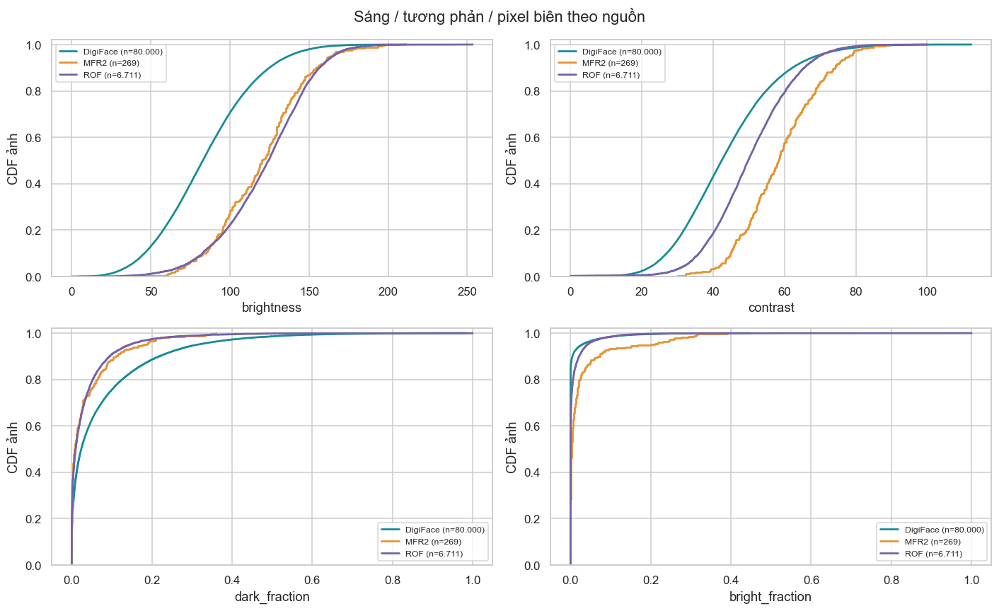

### Diễn giải
Trung vị độ sáng: DigiFace **82,89**, MFR2 **120,32**, ROF **124,40** (thang 0–255). Các nguồn khác nhau rõ, nhưng chênh lệch này còn do cách crop, cách render, màu nền và vật che, không chỉ do chất lượng ảnh.

**Chưa áp CLAHE/cân bằng histogram hàng loạt**, vì các phép này làm lệch phân bố mà model pretrained đã học. Hướng ban đầu: RGB + chuẩn hóa đúng model; brightness jitter nhẹ khi train là cấu hình để thử trên validation. Không được làm sáng riêng ảnh test khó rồi vẫn coi là cùng protocol.


In [17]:
quality_columns=['brightness','contrast','dark_fraction','bright_fraction','blur_laplacian_160',
                 'entropy_bits','saturation_mean','edge_density']
quantile_rows=[]
for (source,condition),g in valid.groupby(['source','condition']):
    for metric in quality_columns:
        q=g[metric].quantile([.01,.05,.25,.5,.75,.95,.99])
        quantile_rows.append({'source':source,'condition':condition,'metric':metric,'n':len(g),
                              **{f'p{int(k*100):02}':float(v) for k,v in q.items()}})
quality_quantiles=pd.DataFrame(quantile_rows);save_table(quality_quantiles,'09_quality_quantiles')
display(quality_quantiles[quality_quantiles.metric.isin(['brightness','contrast'])])
fig,axes=plt.subplots(2,2,figsize=(13,8))
for source,g in valid.groupby('source'):
    for ax,metric in zip(axes.flat,['brightness','contrast','dark_fraction','bright_fraction']):
        ecdf(ax,g[metric],source,SOURCE_COLOR[source]);ax.set(xlabel=metric,ylabel='CDF ảnh')
for ax in axes.flat: ax.legend(fontsize=8)
fig.suptitle('Sáng / tương phản / pixel biên theo nguồn');fig.tight_layout()
finish_figure(fig,'09_light_contrast_clipping')
medians=valid.groupby('source')[['brightness','contrast']].median()
display(Markdown(f"""### Diễn giải
Trung vị độ sáng: DigiFace **{vn(medians.loc['DigiFace','brightness'],2)}**, MFR2 **{vn(medians.loc['MFR2','brightness'],2)}**, ROF **{vn(medians.loc['ROF','brightness'],2)}** (thang 0–255). Các nguồn khác nhau rõ, nhưng chênh lệch này còn do cách crop, cách render, màu nền và vật che, không chỉ do chất lượng ảnh.

**Chưa áp CLAHE/cân bằng histogram hàng loạt**, vì các phép này làm lệch phân bố mà model pretrained đã học. Hướng ban đầu: RGB + chuẩn hóa đúng model; brightness jitter nhẹ khi train là cấu hình để thử trên validation. Không được làm sáng riêng ảnh test khó rồi vẫn coi là cùng protocol.
"""))

## 10. Độ nét, entropy và ảnh ở hai đuôi phân bố

Phương sai Laplacian đo thành phần tần số cao trên bản 160×160: ảnh render 112 phóng lên sẽ mượt hơn, còn viền kính hay khẩu trang lại làm chỉ số tăng. Entropy đo độ đa dạng mức xám và cũng tăng theo nhiễu hoặc nền. **Không chỉ số nào một mình cho biết ảnh mặt có dùng được hay không.**

Vì vậy ta xem cả phân vị lẫn ảnh thật ở hai đuôi. Cờ 1% thấp nhất chỉ dùng để ưu tiên xem lại, không phải lý do để loại đúng 1% dữ liệu.

,source,condition,metric,n,p01,p05,p25,p50,p75,p95,p99
4,DigiFace,synthetic_unannotated,blur_laplacian_160,80000,7.0994,11.9158,22.8266,35.7761,57.2364,124.1196,212.2194
5,DigiFace,synthetic_unannotated,entropy_bits,80000,5.3359,6.0052,6.6402,6.9431,7.1837,7.4533,7.6076
12,MFR2,clean,blur_laplacian_160,98,86.3910,139.9767,401.1481,765.8223,"1,314.7354","2,516.5794","4,497.2606"
13,MFR2,clean,entropy_bits,98,6.5365,6.7279,7.1015,7.3242,7.4880,7.6369,7.7240
20,MFR2,masked,blur_laplacian_160,171,99.3510,161.2065,402.9145,941.3117,"1,679.5378","4,050.4092","5,979.6336"
21,MFR2,masked,entropy_bits,171,6.5092,6.7689,7.1731,7.4110,7.6227,7.7564,7.8478
28,ROF,clean,blur_laplacian_160,4356,6.9049,17.4435,68.3178,173.9866,317.3274,664.2735,"1,154.4465"
29,ROF,clean,entropy_bits,4356,4.5313,6.7335,7.1279,7.3430,7.5108,7.6952,7.7932
36,ROF,masked,blur_laplacian_160,264,6.6507,15.3179,94.9873,242.1253,496.7119,"1,119.6698","1,586.2350"
37,ROF,masked,entropy_bits,264,4.6932,6.1872,6.8183,7.1803,7.4953,7.7168,7.8063


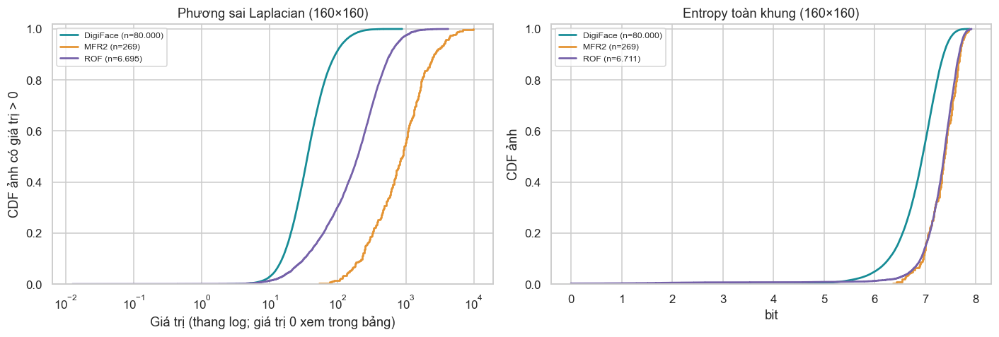

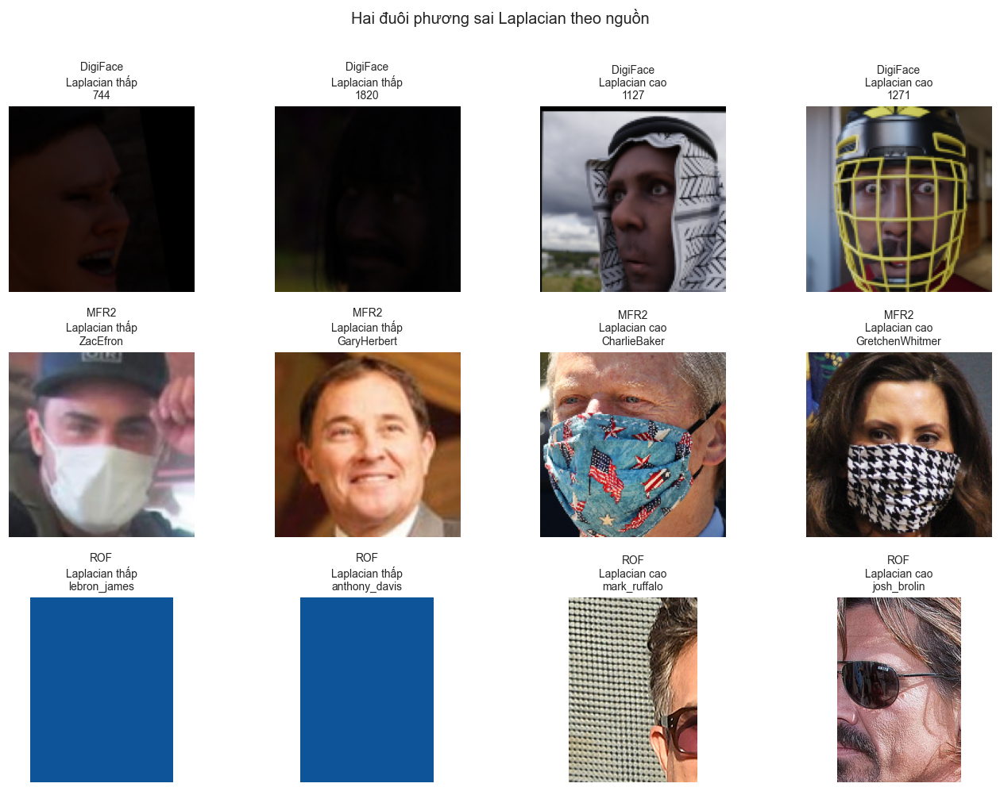

### Kết luận
Không dùng chung một ngưỡng độ nét cho ảnh render 112, MFR2 và ROF. Cần xem ảnh, thử bộ lọc chất lượng trên validation và báo tỷ lệ bị loại theo từng điều kiện. Làm nét hay phóng ảnh không khôi phục được chi tiết danh tính đã mất.

In [18]:
display(quality_quantiles[quality_quantiles.metric.isin(['blur_laplacian_160','entropy_bits'])])
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for source,g in valid.groupby('source'):
    ecdf(axes[0],g.blur_laplacian_160,source,SOURCE_COLOR[source],log=True)
    ecdf(axes[1],g.entropy_bits,source,SOURCE_COLOR[source])
axes[0].set(title='Phương sai Laplacian (160×160)',xlabel='Giá trị (thang log; giá trị 0 xem trong bảng)',ylabel='CDF ảnh có giá trị > 0')
axes[1].set(title='Entropy toàn khung (160×160)',xlabel='bit',ylabel='CDF ảnh')
for ax in axes:ax.legend(fontsize=8)
fig.tight_layout();finish_figure(fig,'10_blur_entropy')
tails=[]
for source,g in valid.groupby('source'):
    a=g.nsmallest(2,'blur_laplacian_160').assign(tail='Laplacian thấp')
    b=g.nlargest(2,'blur_laplacian_160').assign(tail='Laplacian cao')
    tails.append(pd.concat([a,b]))
tails=pd.concat(tails);save_table(tails,'10_blur_tail_selection')
show_raw_grid(tails,'10_blur_tail_examples',title='Hai đuôi phương sai Laplacian theo nguồn',label_cols=('source','tail','identity'))
display(Markdown('### Kết luận\nKhông dùng chung một ngưỡng độ nét cho ảnh render 112, MFR2 và ROF. Cần xem ảnh, thử bộ lọc chất lượng trên validation và báo tỷ lệ bị loại theo từng điều kiện. Làm nét hay phóng ảnh không khôi phục được chi tiết danh tính đã mất.'))

## 11. Quan hệ giữa các chỉ số và khác biệt giữa nguồn

Phần này trả lời hai câu hỏi: các chỉ số chất lượng ảnh có đo trùng nhau không, và các nguồn có khác nhau về thống kê không. Đây không phải thí nghiệm chọn encoder.

- Spearman đo quan hệ đơn điệu, ít bị ảnh hưởng bởi giá trị cực trị hơn Pearson; tương quan không phải quan hệ nhân quả.
- PCA chuẩn hóa các đặc trưng và fit trên mẫu cân bằng giữa các nguồn, không dùng nhãn danh tính.
- Nếu các nguồn tách nhau trên PCA, điều đó phản ánh khác biệt về cách render, độ phân giải hay cách crop, không chứng minh model phân biệt được người.

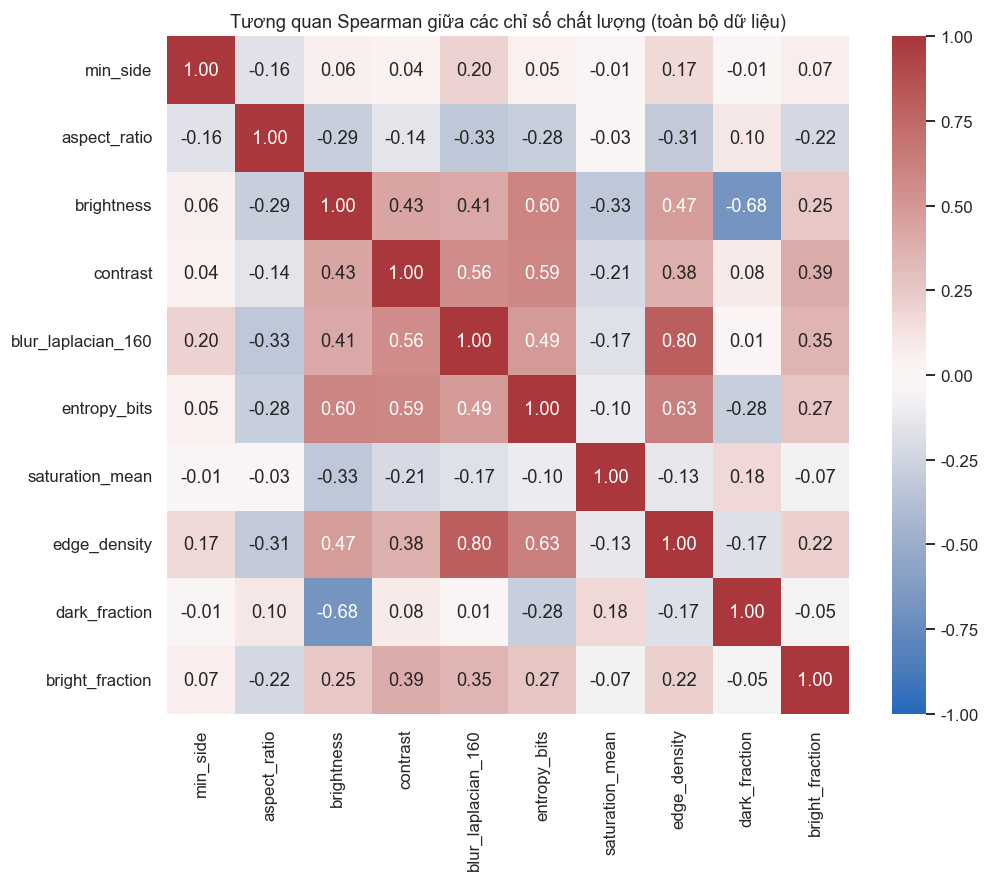

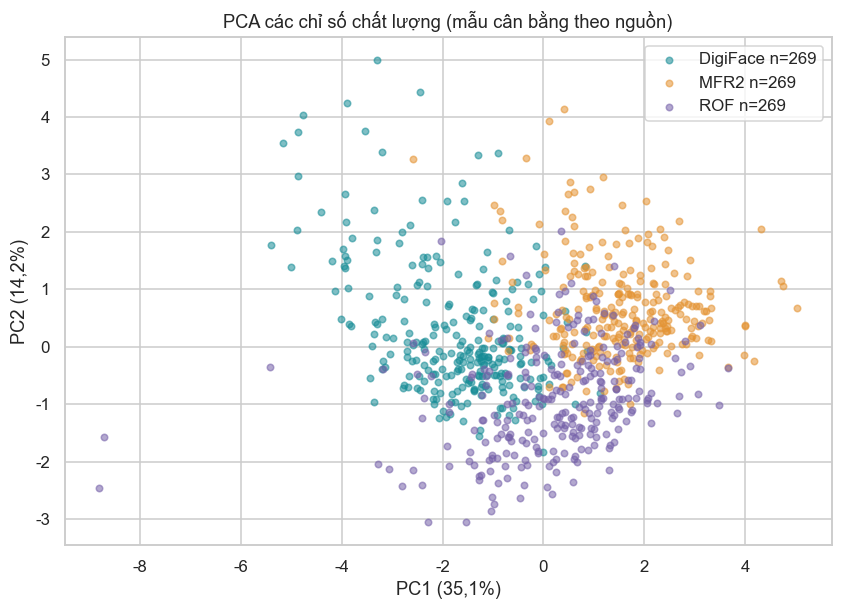

,PC1,PC2
min_side,0.2668,0.2058
aspect_ratio,-0.0371,0.4618
brightness,0.3836,-0.4280
contrast,0.3492,0.2789
blur_laplacian_160,0.4637,0.2346
entropy_bits,0.3449,-0.0545
saturation_mean,-0.2167,0.1359
edge_density,0.4471,0.1575
dark_fraction,-0.1919,0.6132
bright_fraction,0.2016,0.0780


### Diễn giải và giới hạn
PC1 + PC2 giải thích **49,26%** phương sai của **807 ảnh** (cân bằng giữa các nguồn, sau khi chuẩn hóa và lấy log các đặc trưng đã nêu). PCA chỉ tóm tắt các chỉ số chất lượng này, không đại diện cho không gian pixel hay embedding danh tính.

Vì các nguồn phân bố khác nhau, việc đánh giá phải tách ảnh tổng hợp và ảnh thật. Biểu đồ này không phải bằng chứng để chọn FaceNet hay ArcFace, và `StandardScaler` ở đây chỉ dùng cho EDA, không thay cho chuẩn hóa của model pretrained.


,source,feature_a,feature_b,n,spearman
0,DigiFace,edge_density,blur_laplacian_160,80000,0.7725
1,DigiFace,contrast,entropy_bits,80000,0.5704
2,DigiFace,brightness,dark_fraction,80000,-0.6986
3,MFR2,edge_density,blur_laplacian_160,269,0.6633
4,MFR2,contrast,entropy_bits,269,0.3163
5,MFR2,brightness,dark_fraction,269,-0.4297
6,ROF,edge_density,blur_laplacian_160,6711,0.8247
7,ROF,contrast,entropy_bits,6711,0.7474
8,ROF,brightness,dark_fraction,6711,-0.4412


### Các chỉ số không phải những phiếu bầu độc lập
Trên toàn bộ dữ liệu, mật độ cạnh và phương sai Laplacian có Spearman **0,804**; độ sáng và tỷ lệ pixel tối là **-0,680**. Chúng đo những khía cạnh gần nhau, nên cộng nhiều cờ tương quan thành một "điểm chất lượng" sẽ đếm trùng bằng chứng.

Bảng tính riêng từng nguồn cho thấy độ mạnh của các quan hệ phụ thuộc vào nguồn. Vì vậy cần xem ảnh ở đuôi phân bố của từng nguồn và kiểm chứng trên validation; không dùng một ngưỡng Laplacian chung để loại ảnh đeo khẩu trang hay để kết luận ảnh render tốt hơn.


In [19]:
feature_columns=['min_side','aspect_ratio','brightness','contrast','blur_laplacian_160',
                 'entropy_bits','saturation_mean','edge_density','dark_fraction','bright_fraction']
features=valid[feature_columns].replace([np.inf,-np.inf],np.nan)
correlation=features.corr(method='spearman')
save_table(correlation.reset_index(),'11_spearman')
fig,ax=plt.subplots(figsize=(10,8))
sns.heatmap(correlation,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='vlag',ax=ax)
ax.set_title('Tương quan Spearman giữa các chỉ số chất lượng (toàn bộ dữ liệu)')
finish_figure(fig,'11_spearman_quality')

balanced_n=min(500,int(valid.groupby('source').size().min()))
balanced=pd.concat([g.sample(n=balanced_n,random_state=SEED) for _,g in valid.groupby('source')]).copy()
X=balanced[feature_columns].copy()
for col in ['min_side','blur_laplacian_160']:X[col]=np.log1p(X[col])
# Nếu thiếu numeric, không tự impute vào pipeline: chỉ bỏ khỏi phép PCA mô tả này.
keep=np.isfinite(X.to_numpy()).all(axis=1);X=X.loc[keep];balanced=balanced.loc[keep]
scaled=StandardScaler().fit_transform(X)
pca=PCA(n_components=5,random_state=SEED);projection=pca.fit_transform(scaled)
balanced['pc1']=projection[:,0];balanced['pc2']=projection[:,1]
fig,ax=plt.subplots(figsize=(9,6))
for source,g in balanced.groupby('source'):
    ax.scatter(g.pc1,g.pc2,s=18,alpha=.55,label=f'{source} n={len(g)}',color=SOURCE_COLOR[source])
ax.set(xlabel=f'PC1 ({pct(pca.explained_variance_ratio_[0],1)})',ylabel=f'PC2 ({pct(pca.explained_variance_ratio_[1],1)})',
       title='PCA các chỉ số chất lượng (mẫu cân bằng theo nguồn)')
ax.legend();finish_figure(fig,'11_pca_quality_sources')
save_table(balanced[['image_id','source','identity','condition','pc1','pc2']],'11_pca_sample')
loadings=pd.DataFrame(pca.components_.T,index=feature_columns,columns=[f'PC{i+1}' for i in range(5)])
display(loadings.iloc[:,:2])
display(Markdown(f"""### Diễn giải và giới hạn
PC1 + PC2 giải thích **{pct(pca.explained_variance_ratio_[:2].sum())}** phương sai của **{vn(len(balanced))} ảnh** (cân bằng giữa các nguồn, sau khi chuẩn hóa và lấy log các đặc trưng đã nêu). PCA chỉ tóm tắt các chỉ số chất lượng này, không đại diện cho không gian pixel hay embedding danh tính.

Vì các nguồn phân bố khác nhau, việc đánh giá phải tách ảnh tổng hợp và ảnh thật. Biểu đồ này không phải bằng chứng để chọn FaceNet hay ArcFace, và `StandardScaler` ở đây chỉ dùng cho EDA, không thay cho chuẩn hóa của model pretrained.
"""))

proxy_pairs=[('edge_density','blur_laplacian_160'),('contrast','entropy_bits'),
             ('brightness','dark_fraction')]
within=[]
for source,g in valid.groupby('source'):
    for a,b in proxy_pairs:
        within.append({'source':source,'feature_a':a,'feature_b':b,'n':len(g),
                       'spearman':g[[a,b]].corr(method='spearman').loc[a,b]})
within=pd.DataFrame(within);save_table(within,'11_spearman_within_source');display(within)
display(Markdown(f"""### Các chỉ số không phải những phiếu bầu độc lập
Trên toàn bộ dữ liệu, mật độ cạnh và phương sai Laplacian có Spearman **{vn(correlation.loc['edge_density','blur_laplacian_160'],3)}**; độ sáng và tỷ lệ pixel tối là **{vn(correlation.loc['brightness','dark_fraction'],3)}**. Chúng đo những khía cạnh gần nhau, nên cộng nhiều cờ tương quan thành một "điểm chất lượng" sẽ đếm trùng bằng chứng.

Bảng tính riêng từng nguồn cho thấy độ mạnh của các quan hệ phụ thuộc vào nguồn. Vì vậy cần xem ảnh ở đuôi phân bố của từng nguồn và kiểm chứng trên validation; không dùng một ngưỡng Laplacian chung để loại ảnh đeo khẩu trang hay để kết luận ảnh render tốt hơn.
"""))


## 12. Ảnh trùng, mâu thuẫn nhãn và ảnh gần trùng

### 12.1. Trùng tuyệt đối: hai phép hash trả lời hai câu hỏi khác nhau

Một nhóm có thể xuất hiện ở cả hash bytes lẫn hash pixel, nên không cộng số nhóm của hai cách. Ảnh trùng nhưng khác nhãn là mâu thuẫn cần QA; không dùng model sắp được đánh giá để đoán nhãn đúng.

groups  images_in_groups
hash_kind    cross_labels cross_sources                          
pixel_sha256 False        False               4                 8
             True         False               1                 2
sha256       False        False               4                 8
             True         False               1                 2

,image_id,source,identity,condition,path
80423,ROF_ae79cbd3ea0ef65afcf7,ROF,kylian_mbappe,masked,data/benchmark_views/rof/masked/kylian_mbappe/ROF_ae79cbd3ea0ef65afcf7.png
80485,ROF_dc11e620b5e29ef66124,ROF,neymar,masked,data/benchmark_views/rof/masked/neymar/ROF_dc11e620b5e29ef66124.png


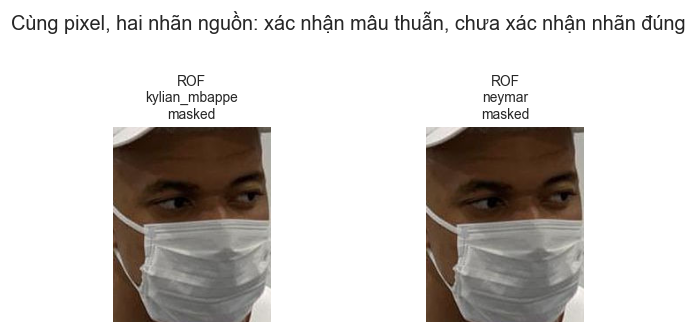

### Diễn giải
Có **5 nhóm trùng pixel**, trong đó **1 nhóm mang nhiều nhãn danh tính**. Cụ thể, cùng một crop vừa có nhãn `kylian_mbappe` vừa có nhãn `neymar`. Ta chỉ kết luận được là nhãn mâu thuẫn, không tự nhận diện người trong ảnh để chọn nhãn đúng.

Ảnh trùng cùng nhãn cần quy tắc giữ một bản hoặc gom vào cùng split. Ảnh trùng khác nhãn cần đối chiếu nguồn độc lập; nếu vẫn không chắc thì giữ trạng thái "chưa xác định" hoặc loại có ghi lý do trước khi khóa test.


In [20]:
duplicate_rows=[]
for kind in ['sha256','pixel_sha256']:
    candidates=valid[valid.duplicated(kind,keep=False)]
    for fingerprint,g in candidates.groupby(kind):
        duplicate_rows.append({'hash_kind':kind,'hash':fingerprint,'n':len(g),
                               'cross_labels':g.canonical_identity.nunique()>1,
                               'cross_sources':g.source.nunique()>1,'image_ids':'|'.join(g.image_id)})
duplicate_groups=pd.DataFrame(duplicate_rows,columns=['hash_kind','hash','n','cross_labels','cross_sources','image_ids'])
save_table(duplicate_groups,'12_exact_duplicate_groups')
display(duplicate_groups.groupby(['hash_kind','cross_labels','cross_sources']).agg(groups=('hash','size'),images_in_groups=('n','sum')))
conflicts=duplicate_groups[(duplicate_groups.hash_kind=='pixel_sha256')&duplicate_groups.cross_labels]
if len(conflicts):
    conflict_ids=conflicts.iloc[0].image_ids.split('|')
    conflict_images=valid[valid.image_id.isin(conflict_ids)]
    display(conflict_images[['image_id','source','identity','condition','path']])
    show_raw_grid(conflict_images,'12_exact_cross_label_case',cols=2,
                  title='Cùng pixel, hai nhãn nguồn: xác nhận mâu thuẫn, chưa xác nhận nhãn đúng')
conflict_example=(' Cụ thể, cùng một crop vừa có nhãn '+' vừa có nhãn '.join(f'`{x}`' for x in conflict_images.identity)+'.'
                  if len(conflicts) else '')
display(Markdown(f"""### Diễn giải
Có **{(duplicate_groups.hash_kind=='pixel_sha256').sum()} nhóm trùng pixel**, trong đó **{len(conflicts)} nhóm mang nhiều nhãn danh tính**.{conflict_example} Ta chỉ kết luận được là nhãn mâu thuẫn, không tự nhận diện người trong ảnh để chọn nhãn đúng.

Ảnh trùng cùng nhãn cần quy tắc giữ một bản hoặc gom vào cùng split. Ảnh trùng khác nhãn cần đối chiếu nguồn độc lập; nếu vẫn không chắc thì giữ trạng thái "chưa xác định" hoặc loại có ghi lý do trước khi khóa test.
"""))

### 12.2. Ảnh gần trùng theo pHash: tạo hàng đợi để xem, không tự gộp

Hai ảnh có khoảng cách Hamming ≤ 4 (trên 64 bit) được coi là ứng viên. Để không phải so mọi cặp (O(n²)), 64 bit được chia thành 5 khối: hai hash khác nhau tối đa 4 bit thì chắc chắn giống nhau ở ít nhất một khối. Ta chỉ so các ảnh chung khối rồi tính Hamming thật, nên không bỏ sót cặp nào ≤ 4, nhưng sẽ có nhiều cặp chỉ giống nhau về bố cục sáng/tối.

candidate_pairs
same_source same_label pixel_equal                 
True        False      False                    351
                       True                       1
            True       False                    132
                       True                       4

,candidate_pairs,zero_distance
involves_near_constant,,
False,368,10
True,120,105


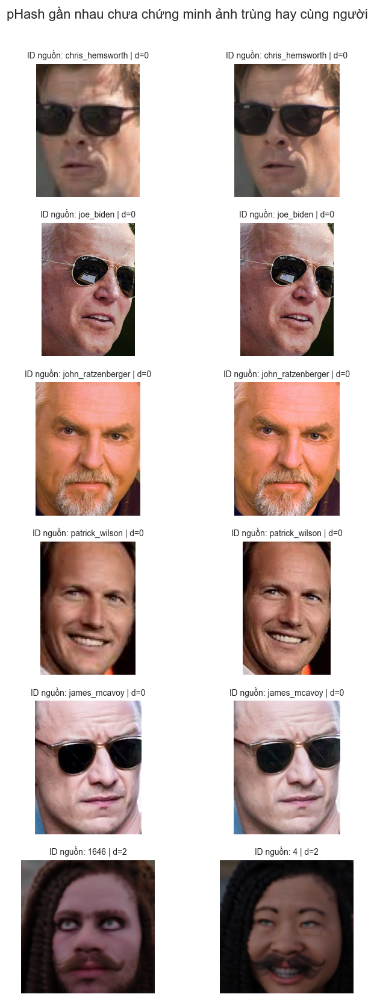

**488 cặp ứng viên** là hàng đợi cần xem, không phải số lỗi nhãn. Chỉ gom nhóm những cặp đã xác minh và ghi lại người xem, quyết định, lý do. Embedding gần nhau cũng không đủ để gộp danh tính.

**120/488 cặp** có ít nhất một ảnh gần như một màu: pHash của các ảnh nền phẳng có thể đều bằng 0 dù khác màu, khác độ sáng. Hình minh họa phía trên chỉ lấy các cặp không trùng pixel và không có ảnh một màu; bảng ứng viên vẫn giữ đủ mọi cặp. Không dùng hình minh họa để ước lượng tỷ lệ sai nhãn.


In [21]:
def find_near_duplicate_pairs(frame,max_distance=4):
    rows=frame.reset_index(drop=True).to_dict('records')
    hashes=[int(r['phash64'],16) for r in rows]
    buckets=[defaultdict(list) for _ in range(5)]
    shifts=[0,13,26,39,52];bits=[13,13,13,13,12]
    pairs=[]
    for i,value in enumerate(hashes):
        candidates=set()
        for bucket,shift,width in zip(buckets,shifts,bits):
            candidates.update(bucket[(value>>shift)&((1<<width)-1)])
        for j in candidates:
            distance=(value^hashes[j]).bit_count()
            if distance<=max_distance:
                a,b=rows[j],rows[i]
                pairs.append({'image_id_a':a['image_id'],'image_id_b':b['image_id'],
                              'path_a':a['path'],'path_b':b['path'],'identity_a':a['identity'],'identity_b':b['identity'],
                              'distance':distance,'same_source':a['source']==b['source'],
                              'same_label':a['canonical_identity']==b['canonical_identity'],
                              'pixel_equal':a['pixel_sha256']==b['pixel_sha256'],'review_status':'pending_visual_review'})
        for bucket,shift,width in zip(buckets,shifts,bits):
            bucket[(value>>shift)&((1<<width)-1)].append(i)
    return pd.DataFrame(pairs)

near_pairs=find_near_duplicate_pairs(valid)
save_table(near_pairs,'12_near_duplicate_candidates')
display(near_pairs.groupby(['same_source','same_label','pixel_equal']).size().rename('candidate_pairs').to_frame())
constant_ids=set(constant.image_id)
near_pairs['involves_near_constant']=near_pairs.image_id_a.isin(constant_ids)|near_pairs.image_id_b.isin(constant_ids)
save_table(near_pairs,'12_near_duplicate_candidates')
constant_pairs=near_pairs.groupby('involves_near_constant').agg(
    candidate_pairs=('distance','size'),zero_distance=('distance',lambda x:int(x.eq(0).sum())))
save_table(constant_pairs.reset_index(),'12_phash_constant_sensitivity');display(constant_pairs)
# Exclusion is for this illustration ONLY, never for the candidate denominator.
examples=near_pairs[~near_pairs.pixel_equal & ~near_pairs.involves_near_constant].sort_values(
    ['distance','image_id_a','image_id_b']).head(6)
fig,axes=plt.subplots(len(examples),2,figsize=(7,len(examples)*2.5),squeeze=False)
for row_axes,row in zip(axes,examples.itertuples()):
    for ax,path,label in zip(row_axes,[row.path_a,row.path_b],[row.identity_a,row.identity_b]):
        with PILImage.open(ROOT/path) as im:ax.imshow(im.convert('RGB'))
        ax.set_title(f'ID nguồn: {label} | d={row.distance}',fontsize=9);ax.axis('off')
fig.suptitle('pHash gần nhau chưa chứng minh ảnh trùng hay cùng người',y=1.005)
fig.tight_layout();finish_figure(fig,'12_near_duplicate_examples')
display(Markdown(f'**{vn(len(near_pairs))} cặp ứng viên** là hàng đợi cần xem, không phải số lỗi nhãn. Chỉ gom nhóm những cặp đã xác minh và ghi lại người xem, quyết định, lý do. Embedding gần nhau cũng không đủ để gộp danh tính.'))
display(Markdown(f"""**{vn(near_pairs.involves_near_constant.sum())}/{vn(len(near_pairs))} cặp** có ít nhất một ảnh gần như một màu: pHash của các ảnh nền phẳng có thể đều bằng 0 dù khác màu, khác độ sáng. Hình minh họa phía trên chỉ lấy các cặp không trùng pixel và không có ảnh một màu; bảng ứng viên vẫn giữ đủ mọi cặp. Không dùng hình minh họa để ước lượng tỷ lệ sai nhãn.
"""))


## 13. Rò rỉ dữ liệu giữa ảnh, cảnh gốc và giữa các nguồn

Chia ngẫu nhiên theo ảnh dễ đưa cùng một người, cùng một cảnh hoặc các biến thể của một ảnh vào cả train lẫn test. Với bài toán nhận diện người mới, phải tách theo danh tính; trong validation/test lại tách gallery, query và unknown. Tuy nhiên khóa `source:identity` không phát hiện được một người xuất hiện ở hai nguồn dưới hai cách viết tên.

Bước chuẩn hóa tên dưới đây chỉ tạo ứng viên trùng tên, không tự gộp. Không thấy tên trùng cũng chưa loại trừ được việc người đó có trong dữ liệu pretraining (VGGFace2).

In [22]:
identities=valid[['source','identity']].drop_duplicates().copy()
identities['normalized_name']=identities.identity.map(lambda x:re.sub('[^a-z0-9]','',x.lower()))
name_overlap=identities[identities.duplicated('normalized_name',keep=False)].sort_values('normalized_name')
save_table(name_overlap,'13_name_overlap_candidates');display(name_overlap)
scene_groups=rof_records.groupby('url').agg(n_labels=('identity','nunique'),n_boxes=('image_id','size'),
                                           n_conditions=('condition','nunique')).reset_index()
shared_scenes=scene_groups[scene_groups.n_labels>1]
save_table(shared_scenes,'13_cross_label_scene_urls')
multi_groups=rof_records.groupby(['annotation_file','annotation_key']).size()
display(pd.DataFrame([{'multiface_annotation_groups':int((multi_groups>1).sum()),
                       'records_in_multiface_groups':int(multi_groups[multi_groups>1].sum()),
                       'scene_URLs_under_multiple_labels':len(shared_scenes)}]))
overlap_names=', '.join('/'.join(g.identity) for _,g in name_overlap.groupby('normalized_name'))
display(Markdown(f"""### Diễn giải
Có **{name_overlap.normalized_name.nunique()} tên chuẩn hóa** xuất hiện ở nhiều nguồn ({overlap_names}) và **{len(shared_scenes)} URL ảnh gốc được dùng cho nhiều nhãn**. Các cặp tên này cần được xác minh trước khi thiết kế các tập độc lập; notebook QA tìm thêm ứng viên viết khác chính tả bằng so khớp gần đúng.

Ảnh gốc có nhiều mặt tự nó không sai; lỗi chỉ xảy ra nếu mọi bbox đều bị gán cùng một tên. Vì vậy QA phải xem cả ảnh gốc lẫn crop. Detector tìm thấy đúng một mặt trong crop cũng chưa xác nhận đó là đúng người.
"""))

,source,identity,normalized_name
80114,MFR2,JoeBiden,joebiden
80369,ROF,joe_biden,joebiden
80122,MFR2,JustinTrudeau,justintrudeau
80406,ROF,justin_trudeau,justintrudeau


,multiface_annotation_groups,records_in_multiface_groups,scene_URLs_under_multiple_labels
0,458,1067,3


### Diễn giải
Có **2 tên chuẩn hóa** xuất hiện ở nhiều nguồn (JoeBiden/joe_biden, JustinTrudeau/justin_trudeau) và **3 URL ảnh gốc được dùng cho nhiều nhãn**. Các cặp tên này cần được xác minh trước khi thiết kế các tập độc lập; notebook QA tìm thêm ứng viên viết khác chính tả bằng so khớp gần đúng.

Ảnh gốc có nhiều mặt tự nó không sai; lỗi chỉ xảy ra nếu mọi bbox đều bị gán cùng một tên. Vì vậy QA phải xem cả ảnh gốc lẫn crop. Detector tìm thấy đúng một mặt trong crop cũng chưa xác nhận đó là đúng người.


## 14. Xem ảnh thật: nối số liệu với hình ảnh

### 14.1. DigiFace có phải toàn ảnh rõ không?

Danh sách ảnh lấy từ lần chọn mẫu cố định trước đó (theo seed). Notebook đọc **ảnh gốc** rồi vẽ lại lưới ảnh kèm ghi chú cho từng ảnh. Hai cách xem bổ sung cho nhau: 48 ảnh ngẫu nhiên (theo ảnh) và 8 danh tính × 6 ảnh (biến thiên trong cùng một người).

Đây là mẫu nhỏ, không dùng để ước lượng tỷ lệ nhãn đúng của 80.000 ảnh.

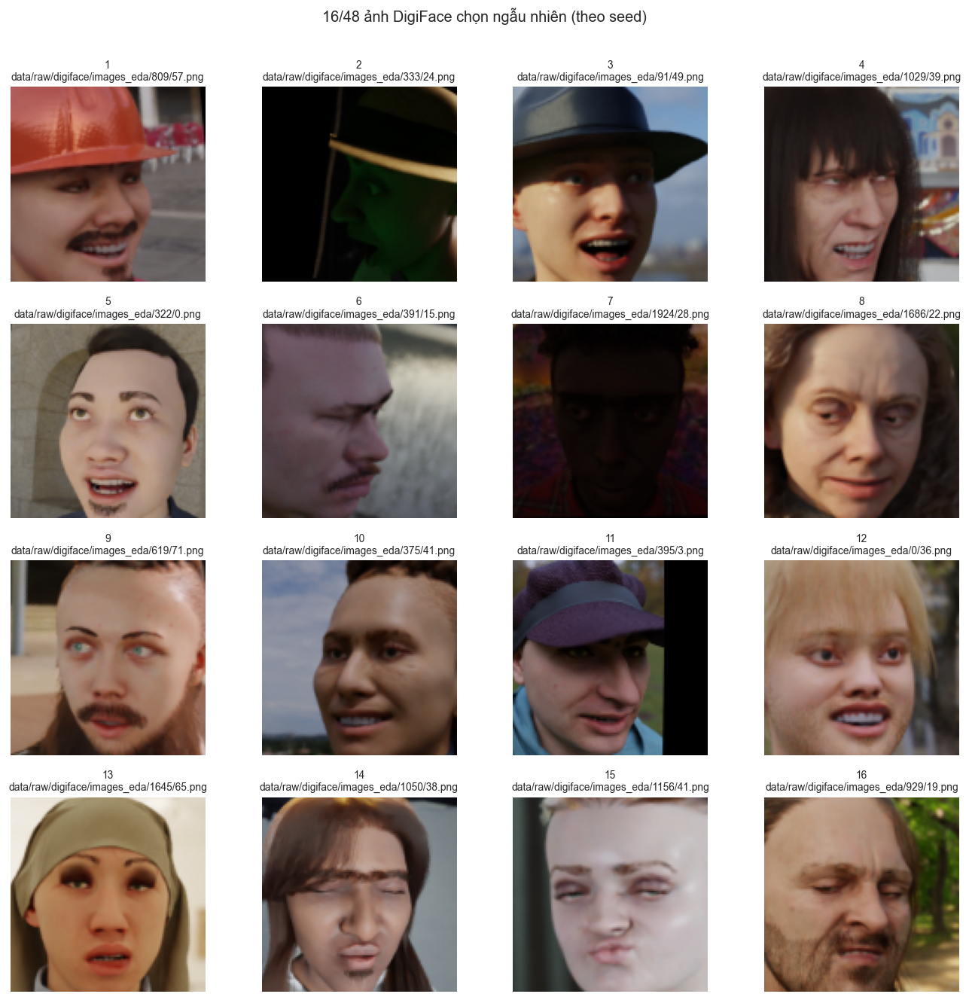

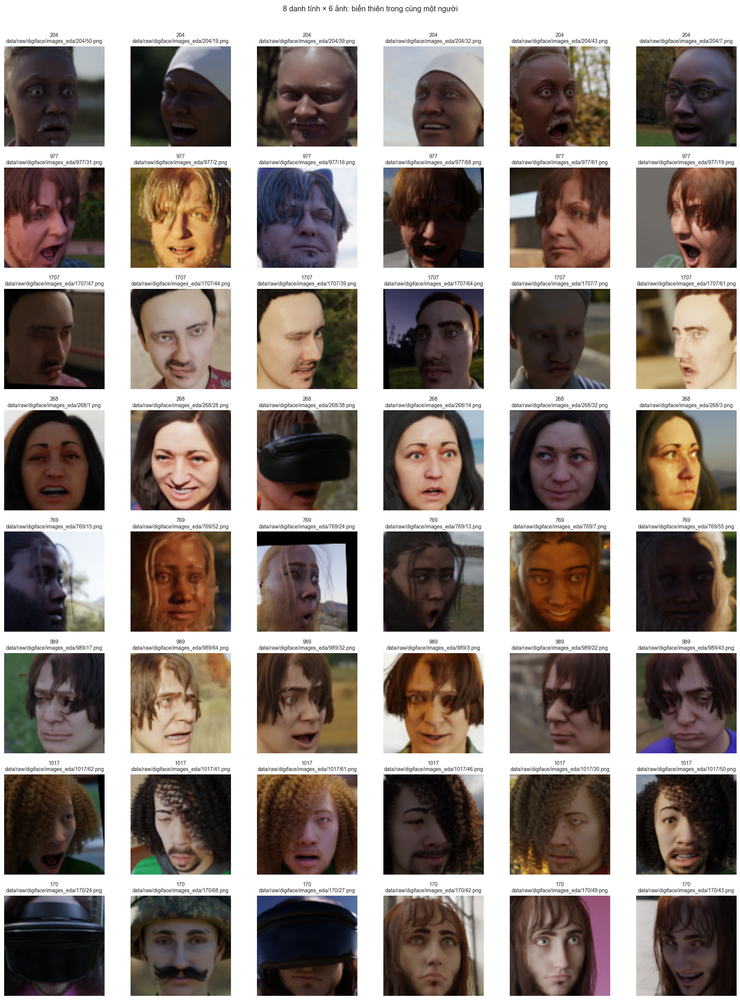

,index,path,observation
0,1,data/raw/digiface/images_eda/809/57.png,Một mặt render nhìn thấy; có biến thiên góc/biểu cảm/ánh sáng; chưa xác minh...
1,2,data/raw/digiface/images_eda/333/24.png,Bóng tối mạnh và mũ; một phần mặt sát mép.
2,3,data/raw/digiface/images_eda/91/49.png,Một mặt render nhìn thấy; có biến thiên góc/biểu cảm/ánh sáng; chưa xác minh...
3,4,data/raw/digiface/images_eda/1029/39.png,Một mặt render nhìn thấy; có biến thiên góc/biểu cảm/ánh sáng; chưa xác minh...
4,5,data/raw/digiface/images_eda/322/0.png,Một mặt render nhìn thấy; có biến thiên góc/biểu cảm/ánh sáng; chưa xác minh...
5,6,data/raw/digiface/images_eda/391/15.png,Một mặt render nhìn thấy; có biến thiên góc/biểu cảm/ánh sáng; chưa xác minh...
6,7,data/raw/digiface/images_eda/1924/28.png,Bóng tối rất mạnh; khó thấy vùng mắt.
7,8,data/raw/digiface/images_eda/1686/22.png,Một mặt render nhìn thấy; có biến thiên góc/biểu cảm/ánh sáng; chưa xác minh...
8,9,data/raw/digiface/images_eda/619/71.png,Một mặt render nhìn thấy; có biến thiên góc/biểu cảm/ánh sáng; chưa xác minh...
9,10,data/raw/digiface/images_eda/375/41.png,Một mặt render nhìn thấy; có biến thiên góc/biểu cảm/ánh sáng; chưa xác minh...


### Diễn giải
Trong cùng một danh tính, góc mặt, biểu cảm, ánh sáng và phụ kiện thay đổi; có ảnh đội mũ che gần hết mắt. Vì vậy **B1 là "dữ liệu nền chưa thêm che nhân tạo"**, còn B2 là cùng dữ liệu nền cộng thêm che. Muốn nói "B1 chỉ train ảnh rõ" thì phải có một subset ảnh rõ được gán nhãn và QA riêng.

Khi mắt đã bị che, bước crop/landmark có thể không ổn định, ảnh hưởng cả detector lẫn encoder. Cần xem overlay landmark và tách riêng các ảnh không đủ thông tin.

In [23]:
df_qa=pd.read_csv(EDA_SNAPSHOT/'digiface_visual_qa_selection.csv',dtype={'identity':str})
subset=df_qa.iloc[:16].copy()
show_raw_grid(subset,'14_digiface_random_16',title='16/48 ảnh DigiFace chọn ngẫu nhiên (theo seed)',label_cols=('index','path'))
within=pd.read_csv(EDA_SNAPSHOT/'digiface_identity_qa_selection.csv',dtype={'identity':str})
show_raw_grid(within,'14_digiface_within_id',cols=6,title='8 danh tính × 6 ảnh: biến thiên trong cùng một người',label_cols=('identity','path'))
display(pd.read_csv(EDA_SNAPSHOT/'digiface_visual_qa_manual_review.csv').loc[:,['index','path','observation']].head(12))
display(Markdown('### Diễn giải\nTrong cùng một danh tính, góc mặt, biểu cảm, ánh sáng và phụ kiện thay đổi; có ảnh đội mũ che gần hết mắt. Vì vậy **B1 là "dữ liệu nền chưa thêm che nhân tạo"**, còn B2 là cùng dữ liệu nền cộng thêm che. Muốn nói "B1 chỉ train ảnh rõ" thì phải có một subset ảnh rõ được gán nhãn và QA riêng.\n\nKhi mắt đã bị che, bước crop/landmark có thể không ổn định, ảnh hưởng cả detector lẫn encoder. Cần xem overlay landmark và tách riêng các ảnh không đủ thông tin.'))

### 14.2. ROF: xem crop lỗi cùng ảnh gốc

Mẫu số 26 và 27 trong lần xem trước có dấu hiệu cần đối chiếu với ảnh gốc. Việc xem ảnh gốc chỉ để kiểm annotation/crop theo quy tắc đặt trước, không dùng lỗi nhận diện trên test để chọn model.

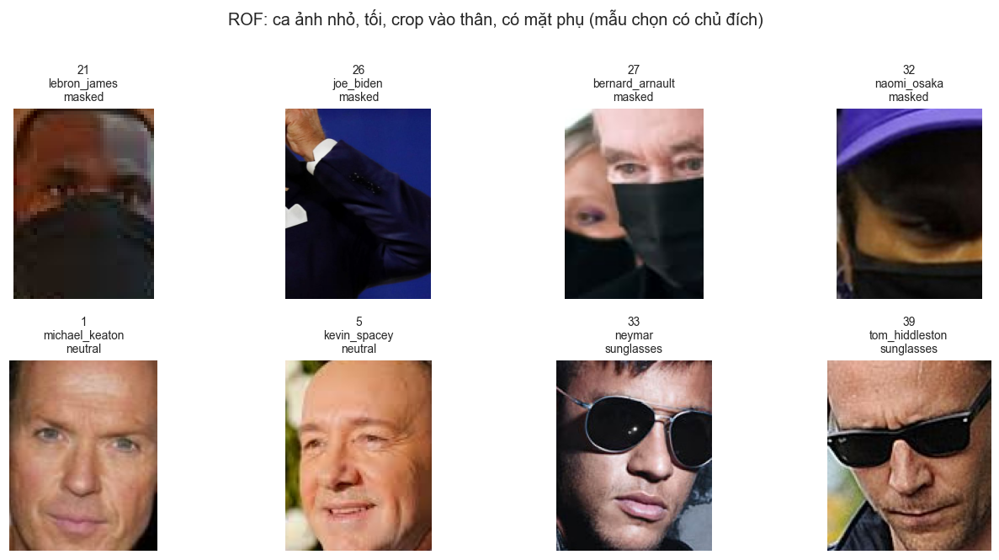

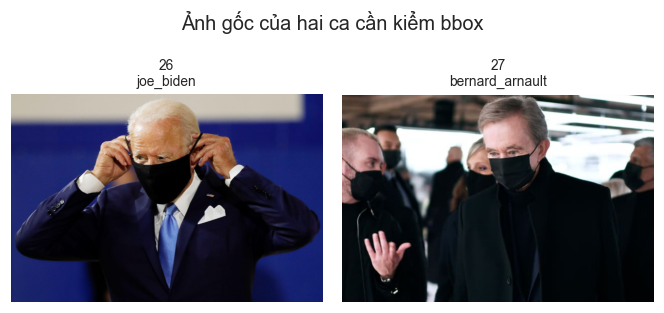

,index,path,observation,decision
20,21,data/benchmark_views/rof/masked/lebron_james/ROF_0067ced578fcb1106134.png,Crop tối/mờ; cần review chất lượng.,no_automatic_exclusion
25,26,data/benchmark_views/rof/masked/joe_biden/ROF_bf5f63f2787669fb894a.png,"Crop chủ yếu là thân/tay/áo; không thấy mặt rõ. Flag sai/vô dụng bbox, không...",flag_for_bbox_review
26,27,data/benchmark_views/rof/masked/bernard_arnault/ROF_3ad2e8131505be08f590.png,Có thêm phần mặt người khác sát mép trái; cần xem cảnh gốc và chọn đúng bbox.,flag_for_bbox_review
31,32,data/benchmark_views/rof/masked/naomi_osaka/ROF_f18e253637192afa6db6.png,"Crop sát mặt, mắt tối; giữ như ca khó cho QA.",no_automatic_exclusion


**Nhận xét:** crop 26 chủ yếu là áo/thân người; crop 27 có thêm một phần mặt người khác ở mép. Cả hai vẫn có `read_ok=True`. Không tự chọn mặt lớn nhất hay dùng model để gán lại nhãn; ghi lý do, người xem và quyết định ở bước QA trước khi khóa protocol.

In [24]:
rof_qa=pd.read_csv(EDA_SNAPSHOT/'rof_visual_qa_selection.csv')
chosen=pd.concat([rof_qa[rof_qa['index'].isin([21,26,27,32])],rof_qa[rof_qa['index'].isin([1,5,33,39])]])
show_raw_grid(chosen,'14_rof_crop_cases',title='ROF: ca ảnh nhỏ, tối, crop vào thân, có mặt phụ (mẫu chọn có chủ đích)',label_cols=('index','identity','condition'))
scene_cases=chosen[chosen['index'].isin([26,27])]
show_raw_grid(scene_cases,'14_rof_original_scenes',cols=2,title='Ảnh gốc của hai ca cần kiểm bbox',
              label_cols=('index','identity'),image_col='original_path')
reviewed=pd.read_csv(EDA_SNAPSHOT/'rof_visual_qa_manual_review.csv')
display(reviewed[reviewed['index'].isin([21,26,27,32])][['index','path','observation','decision']])
display(Markdown('**Nhận xét:** crop 26 chủ yếu là áo/thân người; crop 27 có thêm một phần mặt người khác ở mép. Cả hai vẫn có `read_ok=True`. Không tự chọn mặt lớn nhất hay dùng model để gán lại nhãn; ghi lý do, người xem và quyết định ở bước QA trước khi khóa protocol.'))

## 15. Audit detector: đo trên mẫu nào, đo cái gì?

Cần biết detector làm rơi bao nhiêu ảnh trước khi đánh giá nhận diện. Lưu ý: tỷ lệ detector trả đúng một box **không phải độ chính xác nhận diện**.

Phạm vi cố định:

- Toàn bộ crop ROF thu được và toàn bộ MFR2.
- 2 ảnh mỗi danh tính DigiFace (seed 20261021): phủ đủ 2.000 người mà vẫn tiết kiệm thời gian chạy.
- Tối đa 200 ảnh gốc ROF mỗi điều kiện, tách thành nhóm `ROF_scene`.

Ảnh được thu nhỏ để cạnh dài ≤ 640. Với ảnh gốc có nhiều người, detector trả nhiều box có thể là đúng, chỉ là không khớp chính sách demo một mặt. Crop và ảnh gốc có mẫu số khác nhau nên không so trực tiếp với nhau.

In [25]:
synth=valid[valid.source=='DigiFace']
sampled_synth=synth.groupby('identity',group_keys=False).sample(n=2,random_state=SEED)
real=valid[valid.source!='DigiFace']
scenes=real[real.source=='ROF'].drop_duplicates('original_id').copy()
scenes=pd.concat([g.sample(n=min(200,len(g)),random_state=SEED) for _,g in scenes.groupby('condition')])
scenes['path']=scenes.original_path;scenes['image_id']='SCENE_'+scenes.original_id.str[:20]
scenes['source']='ROF_scene';scenes['identity']='scene_not_a_person_label'
detector_targets=pd.concat([sampled_synth,real,scenes]).sort_values('image_id').reset_index(drop=True)
assert detector_targets.image_id.is_unique
assert sampled_synth.groupby('identity').size().eq(2).all()
save_table(detector_targets[['image_id','source','identity','condition','path']],'15_detector_sample')
display(detector_targets.groupby(['source','condition']).size().rename('audit_inputs').to_frame())

audit_inputs
source    condition                          
DigiFace  synthetic_unannotated          4000
MFR2      clean                            98
          masked                          171
ROF       clean                          4356
          masked                          264
          sunglasses                     2091
ROF_scene clean                           200
          masked                          200
          sunglasses                      200

### Code chạy detector và cách đếm lỗi

Giữ tất cả box, không âm thầm chọn mặt lớn nhất. Ảnh có cạnh < 20 px (sau khi thu nhỏ về 640) được trả trạng thái `input_too_small` trước khi gọi MTCNN, thay vì để thư viện báo lỗi `torch.cat`. Các ảnh này vẫn nằm trong mẫu số và được tính là bị từ chối.

Thông tin hình học chỉ có cho ảnh có đúng một mặt. Box được lưu trước khi cắt theo biên ảnh, kèm landmark và cờ vượt biên. Điểm detector không được dùng làm phần trăm che; ảnh quá nhỏ không được phóng to để che giấu lỗi thu thập.

In [26]:
DETECTOR_SPEC={'version':'mtcnn-audit-v2-explicit-small-input','min_face_size':20,
               'thresholds':[0.6,0.7,0.7],'factor':0.709,'max_side':640,
               'image_size':160,'keep_all':True,'seed':SEED}
detector=MTCNN(image_size=160,margin=0,min_face_size=20,thresholds=[0.6,0.7,0.7],
               factor=.709,post_process=True,keep_all=True,device=DEVICE).eval()

def audit_detector_row(row):
    result={'image_id':row['image_id'],'status':'audit_error','audit_ok':False,'face_count':None}
    try:
        with PILImage.open(ROOT/row['path']) as im:rgb=ImageOps.exif_transpose(im).convert('RGB')
        rgb.thumbnail((640,640),PILImage.Resampling.LANCZOS)
        result.update(audit_width=rgb.width,audit_height=rgb.height)
        if min(rgb.size)<20:
            result.update(status='input_too_small',audit_ok=True,reject_reason='min_side_below20')
            return result
        if torch.cuda.is_available():torch.cuda.synchronize()
        started=time.perf_counter()
        with torch.inference_mode():boxes,scores,landmarks=detector.detect(rgb,landmarks=True)
        if torch.cuda.is_available():torch.cuda.synchronize()
        count=0 if boxes is None else len(boxes)
        result.update(face_count=count,detector_ms=(time.perf_counter()-started)*1000,audit_ok=True,
                      status='no_face' if count==0 else ('single_face' if count==1 else 'multiple_faces'))
        if boxes is not None:
            result.update(boxes=boxes.tolist(),scores=[float(x) for x in scores],landmarks=landmarks.tolist())
            if count==1:
                x1,y1,x2,y2=[float(x) for x in boxes[0]];lm=landmarks[0];eye=lm[1]-lm[0]
                raw_area=max(0,x2-x1)*max(0,y2-y1)
                intersection=max(0,min(rgb.width,x2)-max(0,x1))*max(0,min(rgb.height,y2)-max(0,y1))
                result.update(face_area_fraction=raw_area/(rgb.width*rgb.height),
                              clipped_box_area_fraction=intersection/(rgb.width*rgb.height),
                              face_min_side=min(x2-x1,y2-y1),roll_degrees=float(np.degrees(np.arctan2(eye[1],eye[0]))),
                              max_score=float(scores[0]),box_outside_image=bool(x1<0 or y1<0 or x2>rgb.width or y2>rgb.height))
    except Exception as exc:result.update(error=f'{type(exc).__name__}: {exc}')
    return result

In [27]:
target_state=[]
for row in detector_targets.itertuples():
    st=(ROOT/row.path).stat();target_state.append((row.image_id,row.path,st.st_size,st.st_mtime_ns))
detector_fingerprint=hashlib.sha256(json.dumps([DETECTOR_SPEC,target_state,torch.__version__]).encode()).hexdigest()
det_meta_path=CACHE_DIR/'detector_meta.json';det_log_path=CACHE_DIR/'detector_audit.jsonl'
det_match=det_meta_path.exists() and json.loads(det_meta_path.read_text())['fingerprint']==detector_fingerprint
det_cached={}
if DETECTOR_CACHE_POLICY=='auto' and det_match and det_log_path.exists():
    for line in det_log_path.read_text(encoding='utf-8').splitlines():
        try:r=json.loads(line);det_cached[r['image_id']]=r
        except json.JSONDecodeError:pass
detector_meta={'fingerprint':detector_fingerprint,'config':DETECTOR_SPEC,'device':DEVICE,
               'gpu':environment['gpu'],'completed':False}
det_meta_path.write_text(json.dumps(detector_meta,indent=2),encoding='utf-8')
det_todo=[r for r in detector_targets.to_dict('records') if r['image_id'] not in det_cached]
started=time.perf_counter()
with det_log_path.open('a' if det_match and DETECTOR_CACHE_POLICY=='auto' else 'w',encoding='utf-8') as stream:
    for i,row in enumerate(det_todo,1):
        result=audit_detector_row(row);det_cached[row['image_id']]=result
        stream.write(json.dumps(result)+'\n')
        if i%500==0:
            stream.flush();print(f'Detector {i:,}/{len(det_todo):,}; {time.perf_counter()-started:.1f}s',flush=True)
detector_meta.update(completed=True,newly_computed=len(det_todo),cached_before_run=len(detector_targets)-len(det_todo),
                     elapsed_seconds=time.perf_counter()-started)
det_meta_path.write_text(json.dumps(detector_meta,indent=2),encoding='utf-8')
audit=pd.DataFrame([det_cached[x] for x in detector_targets.image_id])
det=detector_targets.merge(audit,on='image_id',validate='one_to_one')
det['reject']=det.status.ne('single_face')
save_table(det,'15_detector_audit')
display(pd.DataFrame([detector_meta]).drop(columns=['config','fingerprint']))
display(det.groupby(['source','status']).size().unstack(fill_value=0))

,device,gpu,completed,newly_computed,cached_before_run,elapsed_seconds
0,cuda:0,NVIDIA GeForce RTX 4060 Laptop GPU,True,0,11580,0.0004


status,input_too_small,multiple_faces,no_face,single_face
source,,,,
DigiFace,0,1,94,3905
MFR2,0,7,4,258
ROF,14,8,497,6192
ROF_scene,0,147,20,433


## 16. Detector theo điều kiện, mẫu số và độ bất định

Đếm riêng các trường hợp không có mặt, nhiều mặt, ảnh quá nhỏ và lỗi phần mềm. Tất cả đều tính là bị từ chối khi demo yêu cầu đúng một mặt, và đều nằm trong mẫu số. Nếu chỉ báo kết quả trên các crop mà detector tìm thấy mặt, kết quả nhận diện sau này sẽ bị **survivor bias**.

Các ảnh của cùng một người có tương quan với nhau, nên bootstrap lấy mẫu theo danh tính (giữ mọi ảnh của người được chọn), không coi hàng nghìn ảnh là quan sát độc lập. Nhóm `ROF_scene` không có nhãn người tin cậy nên không tính khoảng tin cậy theo người.

,source,condition,n,IDs,zero,one,multiple,too_small,audit_error,reject_rate,cluster_low,cluster_high
0,DigiFace,synthetic_unannotated,4000,2000,94,3905,1,0,0,0.0238,0.0190,0.0285
1,MFR2,clean,98,53,0,97,1,0,0,0.0102,0.0000,0.0316
2,MFR2,masked,171,53,4,161,6,0,0,0.0585,0.0245,0.1006
3,ROF,clean,4356,181,254,4089,4,9,0,0.0613,0.0533,0.0699
4,ROF,masked,264,57,80,184,0,0,0,0.3030,0.2043,0.4071
5,ROF,sunglasses,2091,157,163,1919,4,5,0,0.0823,0.0671,0.0981
6,ROF_scene,clean,200,1,2,141,57,0,0,0.2950,NaN,NaN
7,ROF_scene,masked,200,1,18,141,41,0,0,0.2950,NaN,NaN
8,ROF_scene,sunglasses,200,1,0,151,49,0,0,0.2450,NaN,NaN


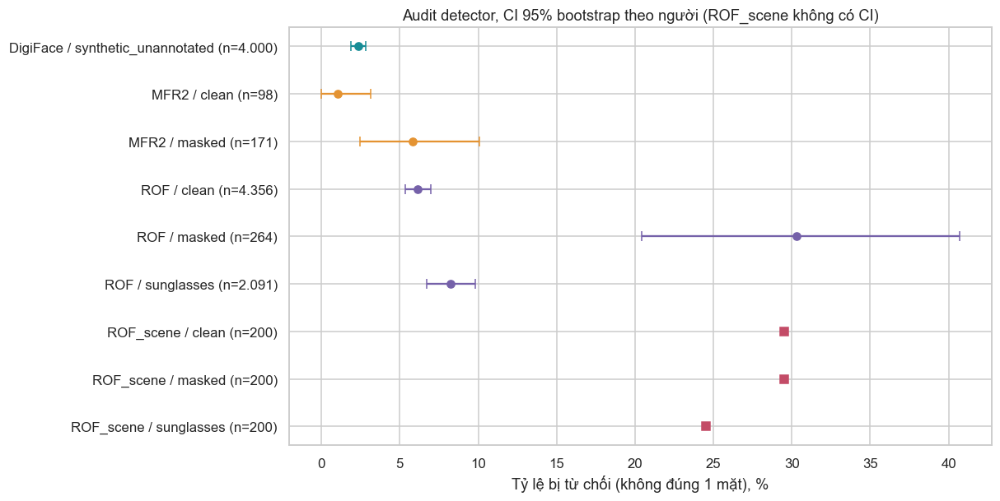

### Diễn giải
Tỷ lệ từ chối cao ở crop ROF đeo khẩu trang gộp cả ảnh nhỏ, box/nhãn chưa QA và tác động thật của khẩu trang, nên chưa thể quy hết cho khẩu trang. Ảnh gốc có nhiều mặt có thể là detector đúng; cần quy tắc chọn đúng annotation cho benchmark, hoặc từ chối trong demo một mặt. Đây chưa phải độ chính xác nhận diện hay số đo tốc độ.

### Kết quả định lượng và hệ quả
Trong **11.580 đầu vào**: **10.788** có đúng một mặt, **615** không tìm thấy mặt, **163** có nhiều mặt, **14** quá nhỏ và **0** lỗi audit khác. "Đúng một mặt" vẫn cần QA để chắc đó là mặt của người trong annotation.

ROF đeo khẩu trang bị từ chối **80/264 = 30,30%**; ROF ảnh rõ **267/4.356 = 6,13%**. Đây là thống kê trên crop ứng viên hiện có, chưa tách ảnh lỗi/ảnh nhỏ và chưa kiểm nhãn. Bảng so sánh trên cùng nhóm người ở dưới giảm bớt khác biệt do thành phần người; pipeline phù hợp phải xác định qua QA và thử preprocessing.

**Cách báo kết quả nhận diện sau này:** báo cả tỷ lệ detector tìm được mặt, kết quả trên ảnh hợp lệ và kết quả end-to-end có tính ảnh bị từ chối. Không loại các ca thất bại khỏi mẫu số.


In [28]:
def cluster_interval(group,repetitions=2000):
    if group.source.iloc[0]=='ROF_scene':return np.nan,np.nan
    units=group.groupby('identity').agg(errors=('reject','sum'),n=('reject','size')).to_numpy()
    if len(units)<2:return np.nan,np.nan
    rng=np.random.default_rng(SEED);rates=[]
    for _ in range(repetitions):
        sample=units[rng.integers(0,len(units),len(units))]
        rates.append(sample[:,0].sum()/sample[:,1].sum())
    return tuple(np.quantile(rates,[.025,.975]))

det_rows=[]
for (source,condition),g in det.groupby(['source','condition']):
    low,high=cluster_interval(g)
    det_rows.append({'source':source,'condition':condition,'n':len(g),'IDs':g.identity.nunique(),
                     'zero':int(g.status.eq('no_face').sum()),'one':int(g.status.eq('single_face').sum()),
                     'multiple':int(g.status.eq('multiple_faces').sum()),'too_small':int(g.status.eq('input_too_small').sum()),
                     'audit_error':int(g.status.eq('audit_error').sum()),'reject_rate':g.reject.mean(),
                     'cluster_low':low,'cluster_high':high})
det_summary=pd.DataFrame(det_rows);save_table(det_summary,'16_detector_condition_summary');display(det_summary)
fig,ax=plt.subplots(figsize=(10,6))
for j,row in det_summary.reset_index(drop=True).iterrows():
    if pd.notna(row.cluster_low):
        error=np.array([[max(0,row.reject_rate-row.cluster_low)],[max(0,row.cluster_high-row.reject_rate)]])*100
        ax.errorbar(row.reject_rate*100,j,xerr=error,fmt='o',color=SOURCE_COLOR[row.source],capsize=4)
    else:ax.plot(row.reject_rate*100,j,'s',color=SOURCE_COLOR[row.source])
ax.set_yticks(range(len(det_summary)),[f'{r.source} / {r.condition} (n={vn(r.n)})' for r in det_summary.itertuples()])
ax.invert_yaxis();ax.set(xlabel='Tỷ lệ bị từ chối (không đúng 1 mặt), %',title='Audit detector, CI 95% bootstrap theo người (ROF_scene không có CI)')
finish_figure(fig,'16_detector_reject_cluster_ci')
display(Markdown('### Diễn giải\nTỷ lệ từ chối cao ở crop ROF đeo khẩu trang gộp cả ảnh nhỏ, box/nhãn chưa QA và tác động thật của khẩu trang, nên chưa thể quy hết cho khẩu trang. Ảnh gốc có nhiều mặt có thể là detector đúng; cần quy tắc chọn đúng annotation cho benchmark, hoặc từ chối trong demo một mặt. Đây chưa phải độ chính xác nhận diện hay số đo tốc độ.'))
states=det.status.value_counts()
masked_rof=det_summary[(det_summary.source=='ROF')&(det_summary.condition=='masked')].iloc[0]
clean_rof=det_summary[(det_summary.source=='ROF')&(det_summary.condition=='clean')].iloc[0]
display(Markdown(f"""### Kết quả định lượng và hệ quả
Trong **{vn(len(det))} đầu vào**: **{vn(states.get('single_face',0))}** có đúng một mặt, **{vn(states.get('no_face',0))}** không tìm thấy mặt, **{vn(states.get('multiple_faces',0))}** có nhiều mặt, **{vn(states.get('input_too_small',0))}** quá nhỏ và **{vn(states.get('audit_error',0))}** lỗi audit khác. "Đúng một mặt" vẫn cần QA để chắc đó là mặt của người trong annotation.

ROF đeo khẩu trang bị từ chối **{vn(masked_rof.n-masked_rof.one)}/{vn(masked_rof.n)} = {pct(masked_rof.reject_rate)}**; ROF ảnh rõ **{vn(clean_rof.n-clean_rof.one)}/{vn(clean_rof.n)} = {pct(clean_rof.reject_rate)}**. Đây là thống kê trên crop ứng viên hiện có, chưa tách ảnh lỗi/ảnh nhỏ và chưa kiểm nhãn. Bảng so sánh trên cùng nhóm người ở dưới giảm bớt khác biệt do thành phần người; pipeline phù hợp phải xác định qua QA và thử preprocessing.

**Cách báo kết quả nhận diện sau này:** báo cả tỷ lệ detector tìm được mặt, kết quả trên ảnh hợp lệ và kết quả end-to-end có tính ảnh bị từ chối. Không loại các ca thất bại khỏi mẫu số.
"""))


### So sánh trên cùng nhóm người: ảnh rõ và ảnh đeo khẩu trang

Chỉ so những người có cả hai điều kiện, mỗi người có trọng số bằng nhau. Tuy vậy, ảnh rõ và ảnh khẩu trang không phải cùng một ảnh chỉ thêm khẩu trang mà còn khác ánh sáng, góc chụp; kết quả **chỉ mang tính mô tả, không phải quan hệ nhân quả**.

In [29]:
paired_results=[]
for source in ['ROF','MFR2']:
    per_id=det[(det.source==source)&det.condition.isin(['clean','masked'])].groupby(['identity','condition']).reject.mean().unstack()
    cohort=per_id.dropna(subset=['clean','masked'])
    delta=(cohort.masked-cohort.clean).to_numpy()
    rng=np.random.default_rng(SEED)
    boot=np.array([delta[rng.integers(0,len(delta),len(delta))].mean() for _ in range(2000)])
    paired_results.append({'source':source,'IDs_with_both':len(cohort),'macro_clean_reject':cohort.clean.mean(),
                           'macro_masked_reject':cohort.masked.mean(),'masked_minus_clean':delta.mean(),
                           'paired_CI_low':np.quantile(boot,.025),'paired_CI_high':np.quantile(boot,.975)})
paired_results=pd.DataFrame(paired_results);save_table(paired_results,'16_same_cohort_comparison');display(paired_results)
display(Markdown('**Hệ quả cho đánh giá:** ngoài bảng tính trên mọi ảnh, báo thêm bảng trên cùng nhóm người kèm số người; chốt protocol trước khi so model. Không chỉnh model theo lỗi nhận diện trên test.'))

,source,IDs_with_both,macro_clean_reject,macro_masked_reject,masked_minus_clean,paired_CI_low,paired_CI_high
0,ROF,57,0.0766,0.2613,0.1847,0.1005,0.2730
1,MFR2,53,0.0094,0.0684,0.0590,0.0097,0.1176


**Hệ quả cho đánh giá:** ngoài bảng tính trên mọi ảnh, báo thêm bảng trên cùng nhóm người kèm số người; chốt protocol trước khi so model. Không chỉnh model theo lỗi nhận diện trên test.

## 17. Bbox, landmark và việc chạy lại detector trên ảnh đã crop

`face_area_fraction` dưới đây là diện tích **box chưa cắt theo biên** chia cho diện tích ảnh (đã thu nhỏ ≤ 640), nên có thể lớn hơn 1. Đây không phải tỷ lệ mặt thật, càng không phải phần trăm bị che. Số liệu hình học chỉ có ở ảnh detector trả đúng một mặt, nên bản thân phân bố đã có thiên lệch chọn mẫu.

Ảnh đã crop sát mặt thường khiến bbox của detector vượt ra ngoài khung; điều này chưa có nghĩa detector sai. Đây là lý do phải phân biệt ảnh đã crop/căn chỉnh sẵn với ảnh toàn cảnh trước khi chốt preprocessing.

n outside  area_median  area_max  \
source    condition                                                    
DigiFace  synthetic_unannotated  3905    3577       0.6891    2.2435   
MFR2      clean                    97       4       0.4088    0.6794   
          masked                  161      12       0.3699    0.8308   
ROF       clean                  4089    4049       1.2678    6.4060   
          masked                  184     165       0.9824    2.2868   
          sunglasses             1919    1882       1.2029    5.3237   
ROF_scene clean                   141       3       0.1184    0.4443   
          masked                  141       2       0.0696    0.3544   
          sunglasses              151       7       0.1110    1.0944   

                                 min_side_max outside_fraction  
source    condition                                             
DigiFace  synthetic_unannotated      144.0809           0.9160  
MFR2      clean                      113.5934           0.0412  
          masked                     132.8232           0.0745  
ROF       clean                    1,243.2734           0.9902  
          masked                     712.4370           0.8967  
          sunglasses               1,198.2196           0.9807  
ROF_scene clean                      309.6728           0.0213  
          masked                     289.8078           0.0142  
          sunglasses                 371.3892           0.0464

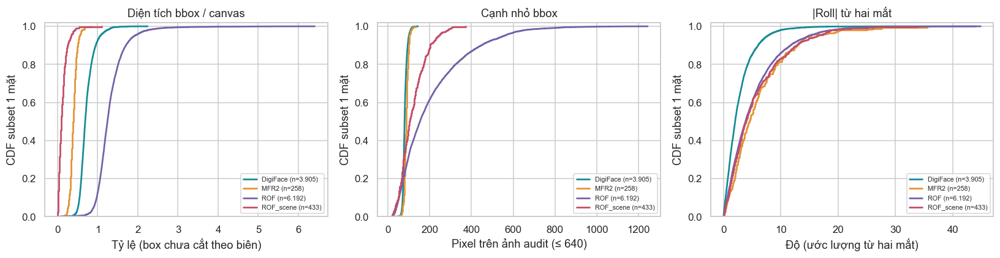

In [30]:
single=det[det.status=='single_face'].copy()
geometry=single.groupby(['source','condition']).agg(
    n=('image_id','size'),outside=('box_outside_image','sum'),
    area_median=('face_area_fraction','median'),area_max=('face_area_fraction','max'),
    min_side_max=('face_min_side','max'))
geometry['outside_fraction']=geometry.outside/geometry.n
save_table(geometry.reset_index(),'17_geometry');display(geometry)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for source,g in single.groupby('source'):
    ecdf(axes[0],g.face_area_fraction,source,SOURCE_COLOR[source])
    ecdf(axes[1],g.face_min_side,source,SOURCE_COLOR[source])
    ecdf(axes[2],g.roll_degrees.abs(),source,SOURCE_COLOR[source])
for ax,title,xlabel in zip(axes,['Diện tích bbox / canvas','Cạnh nhỏ bbox','|Roll| từ hai mắt'],
                           ['Tỷ lệ (box chưa cắt theo biên)','Pixel trên ảnh audit (≤ 640)','Độ (ước lượng từ hai mắt)']):
    ax.set(title=title,xlabel=xlabel,ylabel='CDF subset 1 mặt');ax.legend(fontsize=7)
fig.tight_layout();finish_figure(fig,'17_geometry')

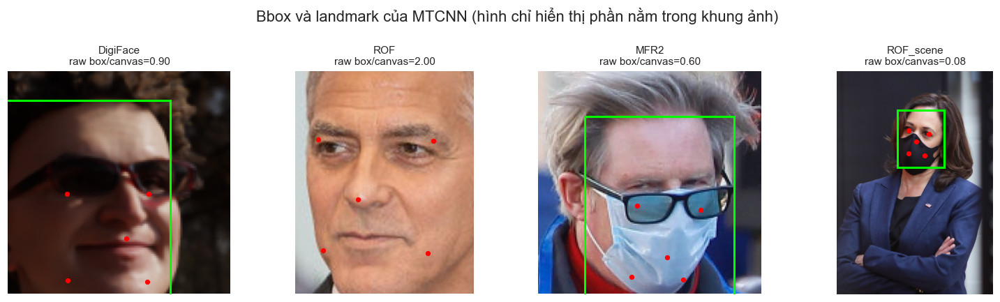

### Phương án preprocessing cần thử
So sánh hai cách: resize thẳng crop của nguồn, và chạy lại detector rồi crop, trên tập thí điểm và validation; xem margin, landmark và phần mặt bị cắt mất. Chỉ thêm căn chỉnh 5 điểm (similarity alignment) sau khi đã QA landmark. Phương án được chọn phải dùng chung cho B0/B1/B2; chưa chạy lại detector hàng loạt cho mọi nguồn.

In [31]:
# Overlay trực tiếp trên ảnh; không ghi crop mới vào dataset.
overlay_cases=pd.concat([
    single[(single.source=='DigiFace')&single.box_outside_image.eq(True)].head(1),
    single[(single.source=='ROF')&single.face_area_fraction.gt(2)].head(1),
    single[single.source=='MFR2'].head(1),single[single.source=='ROF_scene'].head(1)
])
fig,axes=plt.subplots(1,len(overlay_cases),figsize=(14,4))
for ax,row in zip(axes,overlay_cases.itertuples()):
    with PILImage.open(ROOT/row.path) as im:rgb=ImageOps.exif_transpose(im).convert('RGB')
    rgb.thumbnail((640,640),PILImage.Resampling.LANCZOS);ax.imshow(rgb)
    for box,lm in zip(row.boxes,row.landmarks):
        x1,y1,x2,y2=box;ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color='lime',lw=2))
        a=np.array(lm);ax.scatter(a[:,0],a[:,1],s=14,c='red')
    ax.set_xlim(0,rgb.width);ax.set_ylim(rgb.height,0)
    ax.set_title(f'{row.source}\nraw box/canvas={row.face_area_fraction:.2f}',fontsize=10);ax.axis('off')
fig.suptitle('Bbox và landmark của MTCNN (hình chỉ hiển thị phần nằm trong khung ảnh)')
fig.tight_layout();finish_figure(fig,'17_bbox_overlay')
display(Markdown('### Phương án preprocessing cần thử\nSo sánh hai cách: resize thẳng crop của nguồn, và chạy lại detector rồi crop, trên tập thí điểm và validation; xem margin, landmark và phần mặt bị cắt mất. Chỉ thêm căn chỉnh 5 điểm (similarity alignment) sau khi đã QA landmark. Phương án được chọn phải dùng chung cho B0/B1/B2; chưa chạy lại detector hàng loạt cho mọi nguồn.'))

## 18. MFR2: kiểm tra protocol cặp và sự phụ thuộc giữa các mẫu

Trong `pairs.txt`, dòng 3 cột là cặp cùng người (`ID i j`), dòng 4 cột là cặp hai người (`ID1 i ID2 j`). Ta đọc trực tiếp file, đối chiếu tên file và nhãn, tìm cặp lặp, cặp đảo chiều, cặp tự so với chính nó và số lần một ảnh được dùng lại. Protocol của tác giả được giữ nguyên để đối chiếu; bản chỉ gồm các cặp duy nhất (nếu cần) là phân tích độ nhạy riêng.

,pair_rows,positive,negative,unique_undirected,repeated_same_direction,additional_reversed,self_pairs,images_used,images_reused,usage_median,usage_max
0,848,424,424,843,2,3,0,266,252,7.0000,13


b is clean,False,True
a is clean,,
False,396,229
True,154,69


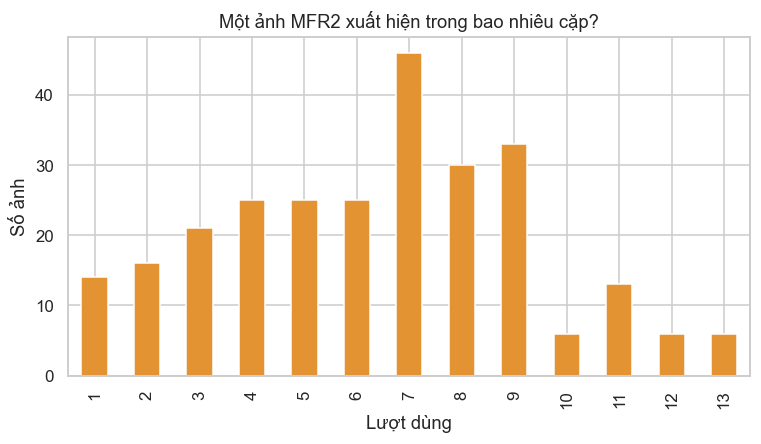

### Diễn giải
**848 dòng** nhưng chỉ có **843 cặp duy nhất** (không tính chiều); **252/266 ảnh** được dùng trong hơn một cặp. Vì vậy không coi 848 dòng là 848 quan sát độc lập khi tính khoảng tin cậy.

Không chia ngẫu nhiên từng cặp vào train/test vì ảnh và người lặp lại giữa các cặp. Khi báo kết quả, dùng đúng file của tác giả và ghi rõ protocol; nếu thay đổi thì báo riêng. Nhãn `surgical_*` chỉ là loại/màu khẩu trang, không có nghĩa là khẩu trang được ghép nhân tạo.


In [32]:
mfr_labels={}
for line in (mfr_base/'mfr2_labels.txt').read_text(encoding='utf-8-sig').splitlines():
    if line.strip():
        identity,index,mask=[x.strip() for x in line.split(',')]
        mfr_labels[(identity,int(index))]=mask

pair_rows=[]
for line_number,line in enumerate((mfr_base/'pairs.txt').read_text(encoding='utf-8-sig').splitlines(),1):
    tokens=line.split()
    if not tokens:continue
    if len(tokens)==3:
        id_a,i,j=tokens;id_b=id_a
    elif len(tokens)==4:id_a,i,id_b,j=tokens
    else:raise ValueError(f'Unexpected MFR2 line {line_number}: {line}')
    a=f'{id_a}/{id_a}_{int(i):04d}.png';b=f'{id_b}/{id_b}_{int(j):04d}.png'
    pair_rows.append({'line':line_number,'a':a,'b':b,'same_person':id_a==id_b,
                      'mask_a':mfr_labels[(id_a,int(i))],'mask_b':mfr_labels[(id_b,int(j))],
                      'exists_a':(mfr_base/a).exists(),'exists_b':(mfr_base/b).exists(),
                      'directed_key':a+'|'+b,'undirected_key':'|'.join(sorted([a,b]))})
pairs=pd.DataFrame(pair_rows)
assert pairs.exists_a.all() and pairs.exists_b.all()
directed_repeats=int(pairs.duplicated('directed_key').sum())
undirected_repeats=int(pairs.duplicated('undirected_key').sum())
usage=pd.Series(pairs.a.tolist()+pairs.b.tolist()).value_counts()
pair_report=pd.DataFrame([{'pair_rows':len(pairs),'positive':int(pairs.same_person.sum()),
                           'negative':int((~pairs.same_person).sum()),'unique_undirected':pairs.undirected_key.nunique(),
                           'repeated_same_direction':directed_repeats,'additional_reversed':undirected_repeats-directed_repeats,
                           'self_pairs':int(pairs.a.eq(pairs.b).sum()),'images_used':len(usage),
                           'images_reused':int(usage.gt(1).sum()),'usage_median':usage.median(),'usage_max':usage.max()}])
save_table(pairs,'18_mfr2_pairs');save_table(usage.rename_axis('file').reset_index(name='appearances'),'18_mfr2_image_usage')
display(pair_report)
display(pd.crosstab(pairs.mask_a.eq('no-mask'),pairs.mask_b.eq('no-mask'),rownames=['a is clean'],colnames=['b is clean']))
fig,ax=plt.subplots(figsize=(8,4))
usage.value_counts().sort_index().plot.bar(ax=ax,color='#E49332')
ax.set(title='Một ảnh MFR2 xuất hiện trong bao nhiêu cặp?',xlabel='Lượt dùng',ylabel='Số ảnh')
finish_figure(fig,'18_mfr2_pair_reuse')
display(Markdown(f"""### Diễn giải
**{vn(len(pairs))} dòng** nhưng chỉ có **{vn(pairs.undirected_key.nunique())} cặp duy nhất** (không tính chiều); **{int(usage.gt(1).sum())}/{len(usage)} ảnh** được dùng trong hơn một cặp. Vì vậy không coi {vn(len(pairs))} dòng là {vn(len(pairs))} quan sát độc lập khi tính khoảng tin cậy.

Không chia ngẫu nhiên từng cặp vào train/test vì ảnh và người lặp lại giữa các cặp. Khi báo kết quả, dùng đúng file của tác giả và ghi rõ protocol; nếu thay đổi thì báo riêng. Nhãn `surgical_*` chỉ là loại/màu khẩu trang, không có nghĩa là khẩu trang được ghép nhân tạo.
"""))

## 19. Chạy thử B0 trong notebook: encoder hoạt động thế nào?

Đây là kiểm tra kỹ thuật, không phải benchmark chọn model. Reference và query cùng đi qua MTCNN (crop, resize, chuẩn hóa) rồi InceptionResnetV1 pretrained; embedding 512 chiều được chuẩn hóa L2 và so bằng cosine. Không train classifier cho 53 người MFR2, không chọn ngưỡng từ vài ảnh, và cosine không phải xác suất.

Trọng số pretrained đã có trong cache của máy tạo notebook; máy mới sẽ tự tải ở lần chạy đầu. Phần EDA không fine-tune.

In [33]:
from typing import Any
def error(code: str, message: str) -> dict[str, str]:
    return {"code": code, "message": message}

def image_record(path: Path) -> dict[str, Any]:
    return {"path": str(path.expanduser().resolve()), "status": "pending", "sha256": None,
            "original_mode": None, "size_after_exif": None, "face_count": None,
            "boxes_xyxy": [], "detector_scores": [], "embedding_dim": None, "error": None}

def extract_embedding(path: Path, detector: Any, encoder: Any, torch: Any,
                      device: Any) -> tuple[dict[str, Any], Any]:
    """Return an auditable record and normalized 1-D embedding, or None on failure."""
    from PIL import Image, ImageOps

    record = image_record(path)
    file_path = Path(record["path"])
    try:
        # pathlib/Pillow avoid OpenCV's Windows Unicode filename pitfalls.
        with file_path.open("rb") as stream:
            digest = hashlib.sha256()
            for chunk in iter(lambda: stream.read(1024 * 1024), b""):
                digest.update(chunk)
            record["sha256"] = digest.hexdigest()
        with Image.open(file_path) as source:
            record["original_mode"] = source.mode
            rgb = ImageOps.exif_transpose(source).convert("RGB")
            rgb.load()
        record["size_after_exif"] = [rgb.width, rgb.height]
    except Exception as exc:
        record.update(status="error", error=error("image_read_failed", f"{type(exc).__name__}: {exc}"))
        return record, None

    # MTCNN cannot build a valid pyramid below its configured min_face_size.
    # Preserve these samples as explicit failures; upscaling would change the protocol.
    minimum_size = int(detector.min_face_size)
    if min(rgb.size) < minimum_size:
        record.update(status="error", error=error(
            "image_too_small",
            f"Image size {rgb.width}x{rgb.height} has a side below MTCNN min_face_size={minimum_size}; image was not enlarged."))
        return record, None

    try:
        with torch.inference_mode():
            # detect all boxes once; never silently select the largest of several people.
            boxes, scores = detector.detect(rgb)
            record["face_count"] = 0 if boxes is None else len(boxes)
            if boxes is not None:
                record["boxes_xyxy"] = [[float(x) for x in box] for box in boxes]
                record["detector_scores"] = [float(x) for x in scores]
            if record["face_count"] != 1:
                code = "no_face" if record["face_count"] == 0 else "multiple_faces"
                record.update(status="error", error=error(code, "Exactly one detected face is required."))
                return record, None
            # extract applies the same crop and (x - 127.5) / 128 to both sides.
            crops = detector.extract(rgb, boxes, save_path=None)
            if crops is None or tuple(crops.shape) != (1, 3, 160, 160):
                raise ValueError("Unexpected face crop shape")
            raw = encoder(crops.to(device))[0]
            if raw.numel() != 512 or not bool(torch.isfinite(raw).all()):
                raise ValueError("Embedding must contain 512 finite values")
            norm = torch.linalg.vector_norm(raw)
            if not bool(norm > 1e-12):
                raise ValueError("Embedding norm is zero")
            embedding = (raw / norm).detach().cpu()
            record.update(status="ok", embedding_dim=512)
            return record, embedding
    except Exception as exc:
        record.update(status="error", error=error("inference_failed", f"{type(exc).__name__}: {exc}"))
        return record, None

In [34]:
encoder=InceptionResnetV1(pretrained='vggface2',classify=False).eval().to(DEVICE)
reference_path=mfr_base/'BenAffleck/BenAffleck_0003.png'
reference_record,reference_embedding=extract_embedding(reference_path,detector,encoder,torch,torch.device(DEVICE))
assert reference_embedding is not None,reference_record
queries=[('self','BenAffleck/BenAffleck_0003.png'),
         ('same_ID_other_clean','BenAffleck/BenAffleck_0007.png'),
         ('same_ID_masked','BenAffleck/BenAffleck_0004.png'),
         ('different_source_ID','AhmadAli/AhmadAli_0002.png')]
smoke_rows=[]
for case,path in queries:
    record,embedding=extract_embedding(mfr_base/path,detector,encoder,torch,torch.device(DEVICE))
    score=float(torch.dot(reference_embedding,embedding).clamp(-1,1)) if embedding is not None else np.nan
    smoke_rows.append({'case':case,'path':path,'status':record['status'],'face_count':record['face_count'],
                       'cosine':score,'error':record['error']})
smoke=pd.DataFrame(smoke_rows);save_table(smoke,'19_b0_smoke');display(smoke)
assert smoke.iloc[0].cosine>1-1e-5
display(Markdown('### Diễn giải\nCosine của ảnh với chính nó ≈ 1 xác nhận pipeline nhất quán; các cặp còn lại cho thấy code chạy được trên ảnh thật và ảnh đeo khẩu trang. **Bốn query không đủ để kết luận về độ chính xác, khả năng chịu khẩu trang hay chọn ngưỡng.** Việc so pretrained với fine-tune phải dùng protocol độc lập, đủ nhiều cặp khác người và ngưỡng chọn trên validation.\n\nVGGFace2 (dữ liệu pretraining) có thể chứa chính các người nổi tiếng trong benchmark. Người không có trong tập fine-tune chưa chắc là chưa từng xuất hiện khi pretraining; cần nêu giới hạn này trên slide.'))

,case,path,status,face_count,cosine,error
0,self,BenAffleck/BenAffleck_0003.png,ok,1,1.0000,None
1,same_ID_other_clean,BenAffleck/BenAffleck_0007.png,ok,1,0.8152,None
2,same_ID_masked,BenAffleck/BenAffleck_0004.png,ok,1,0.4765,None
3,different_source_ID,AhmadAli/AhmadAli_0002.png,ok,1,-0.0429,None


### Diễn giải
Cosine của ảnh với chính nó ≈ 1 xác nhận pipeline nhất quán; các cặp còn lại cho thấy code chạy được trên ảnh thật và ảnh đeo khẩu trang. **Bốn query không đủ để kết luận về độ chính xác, khả năng chịu khẩu trang hay chọn ngưỡng.** Việc so pretrained với fine-tune phải dùng protocol độc lập, đủ nhiều cặp khác người và ngưỡng chọn trên validation.

VGGFace2 (dữ liệu pretraining) có thể chứa chính các người nổi tiếng trong benchmark. Người không có trong tập fine-tune chưa chắc là chưa từng xuất hiện khi pretraining; cần nêu giới hạn này trên slide.

## 20. Từ phát hiện EDA đến hàng đợi QA

Các cờ dưới không xóa ảnh hay đổi nhãn, chỉ sắp thứ tự công việc cho A/C:

- **P0:** trùng pixel nhưng khác nhãn, ảnh gần như một màu, ảnh quá nhỏ cho detector.
- **P1:** annotation có nhiều bbox, cạnh nhỏ < 80 px, tỷ lệ khung bất thường.
- **P2:** 1% ở hai đuôi độ sáng và 1% thấp nhất của tương phản/độ nét trong từng nguồn, để xem lại.
- Bbox vượt khung chỉ là thông tin audit; **crop sát mặt không tự động bị coi là lỗi**.

Hàng đợi có `decision=pending`, cột người kiểm và lý do để trống. Khi sửa sau này, giữ nguyên raw và tạo manifest phiên bản mới.

In [35]:
qa_flags=defaultdict(set)
for group in conflicts.itertuples():
    for image_id in group.image_ids.split('|'):qa_flags[image_id].add('P0_exact_pixel_cross_label')
for image_id in constant.image_id:qa_flags[image_id].add('P0_near_constant_review')
for image_id in det.loc[det.status=='input_too_small','image_id']:qa_flags[image_id].add('P0_detector_input_too_small')
multi_keys=set(multi_groups[multi_groups>1].index)
for row in rof_records.itertuples():
    if (row.annotation_file,row.annotation_key) in multi_keys and row.crop_ok:
        qa_flags[row.image_id].add('P1_multiface_annotation_verify_target')
for source,g in valid.groupby('source'):
    masks={'P1_min_side_lt80':g.min_side<80,
           'P1_aspect_outside_0_5_to2':~g.aspect_ratio.between(.5,2)}
    for metric in ['brightness','contrast','blur_laplacian_160']:
        masks[f'P2_{metric}_bottom1pct']=g[metric]<g[metric].quantile(.01)
        if metric=='brightness':masks['P2_brightness_top1pct']=g[metric]>g[metric].quantile(.99)
    for reason,mask in masks.items():
        for image_id in g.loc[mask,'image_id']:qa_flags[image_id].add(reason)
queue=valid[valid.image_id.isin(qa_flags)].copy()
queue['reasons']=queue.image_id.map(lambda x:'|'.join(sorted(qa_flags[x])))
queue['priority']=queue.reasons.map(lambda x:'P0' if 'P0_' in x else ('P1' if 'P1_' in x else 'P2'))
queue['decision']='pending';queue['reviewer']='';queue['review_note']=''
queue=queue.sort_values(['priority','source','image_id'])
save_table(queue,'20_QA_review_queue')
display(queue.groupby(['priority','source']).size().unstack(fill_value=0))
show_table(queue[['image_id','source','identity','priority','reasons','decision']],15)
display(Markdown(f'**{vn(len(queue))} ảnh/crop có ít nhất một cờ QA**. Đây là số ảnh cần xem, không phải số ảnh sai. Mỗi ảnh chỉ được đếm một lần dù có nhiều lý do; mỗi dòng có mức ưu tiên và liên kết tới annotation/nhãn để nhóm xử lý tiếp.'))

source,DigiFace,MFR2,ROF
priority,,,
P0,0,0,34
P1,0,0,2294
P2,2363,12,107


,image_id,source,identity,priority,reasons,decision
82079,ROF_001ef20aca64d04d23d3,ROF,giannis_antetokounmpo,P0,P0_near_constant_review|P1_min_side_lt80|P2_blur_laplacian_160_bottom1pct|P2...,pending
82340,ROF_0801a7a8303080cfe06a,ROF,james_harden,P0,P0_near_constant_review|P2_blur_laplacian_160_bottom1pct|P2_contrast_bottom1pct,pending
84064,ROF_0af7b7d4e391a944376c,ROF,petra_kvitova,P0,P0_near_constant_review|P2_blur_laplacian_160_bottom1pct|P2_contrast_bottom1pct,pending
81500,ROF_13909ad015a1143bfe78,ROF,diego_schwartzman,P0,P0_near_constant_review|P2_blur_laplacian_160_bottom1pct|P2_brightness_top1p...,pending
85131,ROF_2fcf1fb9bb3eaecafcdd,ROF,bryce_dallas_howard,P0,P0_detector_input_too_small|P1_min_side_lt80|P2_blur_laplacian_160_bottom1pct,pending
82702,ROF_3140faaba060e40fe54f,ROF,joe_manchin,P0,P0_detector_input_too_small|P1_min_side_lt80|P2_blur_laplacian_160_bottom1pct,pending
80730,ROF_324d54f5d64342c62dda,ROF,arnold_schwarzenegger,P0,P0_near_constant_review|P1_multiface_annotation_verify_target|P2_blur_laplac...,pending
85861,ROF_36c4ee32e3d0c9f678f7,ROF,jason_momoa,P0,P0_detector_input_too_small|P1_min_side_lt80|P1_multiface_annotation_verify_...,pending
81472,ROF_3a490b35f9f620a6e156,ROF,dick_durbin,P0,P0_detector_input_too_small|P1_min_side_lt80|P2_blur_laplacian_160_bottom1pct,pending
85136,ROF_411fffc248dd7b4cc62d,ROF,bryce_dallas_howard,P0,P0_detector_input_too_small|P1_min_side_lt80,pending


*Hiển thị 15/4.810 dòng; bảng đầy đủ nằm trong file CSV.*

**4.810 ảnh/crop có ít nhất một cờ QA**. Đây là số ảnh cần xem, không phải số ảnh sai. Mỗi ảnh chỉ được đếm một lần dù có nhiều lý do; mỗi dòng có mức ưu tiên và liên kết tới annotation/nhãn để nhóm xử lý tiếp.

## 21. EDA hỗ trợ chọn preprocessing và model tới đâu?

### 21.1. Bằng chứng → đề xuất → cách kiểm chứng

Lập luận đi từ dữ liệu tới đề xuất, không đi ngược lại. Những quyết định chưa được kiểm bằng thí nghiệm nhận diện chỉ ghi là **đề xuất**. Việc đã xem thống kê của nguồn đánh giá không cho phép dùng benchmark test để tinh chỉnh sau khi đã khóa protocol.

In [36]:
decisions=pd.DataFrame([
    ['Kích thước gốc 112/160; crop nhỏ/méo','RGB, xử lý EXIF, giữ metadata gốc; resize 160 theo encoder','So khớp tensor online/offline và QA crop nhỏ','Phóng ảnh không khôi phục được chi tiết'],
    ['Input đã crop và bbox thường vượt biên','Phân biệt pre-cropped/aligned với scene; thử direct-resize vs redetect','Tập thí điểm + validation, cùng policy B0/B1/B2','Không gọi mọi bbox ngoài khung là lỗi'],
    ['Brightness/blur khác giữa nguồn','Chưa áp ngưỡng loại chung hoặc CLAHE hàng loạt','Validation theo source/condition; báo rejection coverage','Proxy không là nhãn chất lượng mặt chuẩn'],
    ['Pixel-identical nhưng hai nhãn','QA nhãn, original URL và alias trước split','A/C đối chiếu nguồn; uncertain có lý do','Không tự relabel bằng model đánh giá'],
    ['DigiFace đã có phụ kiện/che','B1 nền chưa thêm che; B2 cùng nền có che bổ sung','Cùng init/steps/batch/tuning budget','Không gọi B1 là toàn ảnh clean'],
    ['Synthetic–real domain gap','DigiFace train-candidate; real benchmark giữ ngoài train','So B0/B1/B2 trên protocol khóa; thêm webcam','PCA quality không chứng minh encoder nào tốt'],
    ['Detector từ chối và input quá nhỏ','Giữ lỗi trong end-to-end denominator; return reason rõ','Report conditional và toàn pipeline','Không chỉ đánh giá survivor crops'],
    ['MFR2 dùng lại ảnh/người giữa các cặp','Giữ protocol cặp riêng; CI theo cụm phù hợp','Không chia ngẫu nhiên từng cặp','848 dòng không phải 848 mẫu độc lập'],
],columns=['bằng chứng','đề xuất','kiểm chứng tiếp','giới hạn'])
save_table(decisions,'21_evidence_decisions')
display(decisions.style.set_properties(**{'white-space':'normal','text-align':'left'}).hide(axis='index'))

bằng chứng,đề xuất,kiểm chứng tiếp,giới hạn
Kích thước gốc 112/160; crop nhỏ/méo,"RGB, xử lý EXIF, giữ metadata gốc; resize 160 theo encoder",So khớp tensor online/offline và QA crop nhỏ,Phóng ảnh không khôi phục được chi tiết
Input đã crop và bbox thường vượt biên,Phân biệt pre-cropped/aligned với scene; thử direct-resize vs redetect,"Tập thí điểm + validation, cùng policy B0/B1/B2",Không gọi mọi bbox ngoài khung là lỗi
Brightness/blur khác giữa nguồn,Chưa áp ngưỡng loại chung hoặc CLAHE hàng loạt,Validation theo source/condition; báo rejection coverage,Proxy không là nhãn chất lượng mặt chuẩn
Pixel-identical nhưng hai nhãn,"QA nhãn, original URL và alias trước split",A/C đối chiếu nguồn; uncertain có lý do,Không tự relabel bằng model đánh giá
DigiFace đã có phụ kiện/che,B1 nền chưa thêm che; B2 cùng nền có che bổ sung,Cùng init/steps/batch/tuning budget,Không gọi B1 là toàn ảnh clean
Synthetic–real domain gap,DigiFace train-candidate; real benchmark giữ ngoài train,So B0/B1/B2 trên protocol khóa; thêm webcam,PCA quality không chứng minh encoder nào tốt
Detector từ chối và input quá nhỏ,Giữ lỗi trong end-to-end denominator; return reason rõ,Report conditional và toàn pipeline,Không chỉ đánh giá survivor crops
MFR2 dùng lại ảnh/người giữa các cặp,Giữ protocol cặp riêng; CI theo cụm phù hợp,Không chia ngẫu nhiên từng cặp,848 dòng không phải 848 mẫu độc lập


### 21.2. Vì sao chọn embedding pretrained làm mốc ban đầu?

- Bài toán cần đăng ký người mới bằng gallery và có người lạ (unknown). Encoder sinh embedding rồi so cosine phù hợp hơn một classifier chỉ biết các người trong tập train.
- InceptionResnetV1 pretrained (facenet-pytorch) là **mốc thực dụng, kiểm chứng được**: trọng số PyTorch đã chạy, đầu vào 160, embedding 512 chiều, có sẵn API fine-tune. Đây không phải lựa chọn SOTA.
- MTCNN là detector baseline có log đầy đủ. EDA cho thấy cần QA crop/landmark và chính sách một mặt; chưa có bằng chứng nó là detector tốt nhất khi mặt bị che.
- ArcFace/InsightFace là phần đối chiếu mở rộng khi protocol và preprocessing đã ổn định. Để đo riêng tác dụng của việc thêm che, B1/B2 phải cùng kiến trúc, cùng loss và cùng ngân sách train.
- Classifier tạm chỉ dùng để học các danh tính trong train; checkpoint được chọn bằng đánh giá embedding trên những người riêng của validation. Accuracy của classifier trên train không chứng minh khả năng nhận diện người mới.

**EDA chưa trả lời được:** model nào tốt hơn trên test, ngưỡng cuối là bao nhiêu, fine-tune có chắc cải thiện không, webcam đạt bao nhiêu FPS. Đó là phần thực nghiệm tiếp theo.

## 22. Kiểm tra nhất quán

Cell dưới kiểm tra tính nhất quán của dữ liệu và kết quả trong notebook (không phải kết quả nhận diện), đồng thời lưu dấu vân tay của dữ liệu và cấu hình vào `notebook_outputs/execution_summary.json`.

In [37]:
assert df.image_id.is_unique
assert df['split'].eq('unassigned').all()
assert df[df.source=='DigiFace'].identity.nunique()==len(archive_id_counts)
assert df[df.source=='DigiFace'].groupby('identity').size().eq(40).all()
assert len(det)==len(detector_targets) and det.image_id.is_unique
assert det_summary.n.sum()==len(det)
assert (det_summary[['zero','one','multiple','too_small','audit_error']].sum(axis=1)==det_summary.n).all()
assert int(det_summary.one.sum())==int(det.status.eq('single_face').sum())
assert pairs.exists_a.all() and pairs.exists_b.all()
assert float(smoke.iloc[0].cosine)>1-1e-5
execution_summary={'pixel_images':len(df),'readable':int(df.read_ok.sum()),
                   'source_counts':df.groupby('source').size().to_dict(),
                   'detector_inputs':len(det),'detector_states':det.status.value_counts().to_dict(),
                   'pixel_duplicate_groups':int((duplicate_groups.hash_kind=='pixel_sha256').sum()),
                   'near_duplicate_candidates':len(near_pairs),'QA_queue':len(queue),
                   'mfr2_pair_rows':len(pairs),'mfr2_unique_undirected':int(pairs.undirected_key.nunique()),
                   'pixel_fingerprint':pixel_fingerprint,'detector_fingerprint':detector_fingerprint,
                   'environment':environment,
                   'stop_point':'acquisition + EDA; no batch preprocessing, split assignment or fine-tuning',
                   'checks':'PASS'}
(OUT_DIR/'execution_summary.json').write_text(json.dumps(execution_summary,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame([{'check':'Consistency assertions','result':'PASS'},
                       {'check':'Split remains unassigned','result':'PASS'},
                       {'check':'B0 self cosine','result':f'{smoke.iloc[0].cosine:.6f}'},
                       {'check':'Raw DigiFace SHA match','result':f'{vn(len(crosscheck))}/{vn(len(crosscheck))}'}]))

,check,result
0,Consistency assertions,PASS
1,Split remains unassigned,PASS
2,B0 self cosine,1.000000
3,Raw DigiFace SHA match,80.000/80.000


### Giới hạn cần nói rõ khi thuyết trình

1. Chưa kiểm bằng mắt toàn bộ nhãn danh tính; mẫu QA và hàng đợi không có nghĩa dữ liệu đã sạch.
2. ROF là bản crawl từ các URL còn sống; link chết, ảnh giữ chỗ và crop lỗi làm nó khác bản công bố. Chưa gọi đây là tái lập benchmark chuẩn khi protocol và nhãn chưa chốt.
3. Chưa có thông tin phiên chụp tin cậy cho ảnh web/render, chưa có dữ liệu webcam, chưa đối chiếu hết khả năng trùng người với dữ liệu pretraining.
4. Các chỉ số chất lượng đo trên toàn khung ảnh; PCA của chúng không thay được việc đánh giá embedding.
5. Audit detector giữ cả ảnh bị từ chối; khoảng tin cậy theo người chỉ mô tả mẫu audit, không sửa được thiên lệch do thu thập hay do nhãn.
6. Fine-tune có thể làm kết quả kém đi. Một thí nghiệm đối chứng đúng vẫn có giá trị nếu giải thích được nguyên nhân.

In [38]:
display(Markdown(f"""## 23. Kết luận phần dữ liệu và EDA

### Những gì đã kiểm chứng bằng code
1. Đã kiểm pixel **{vn(len(df))} ảnh**, đọc được **{vn(df.read_ok.sum())}** ảnh. Archive DigiFace có **{vn(len(archive_entries))}** ảnh; EDA pixel chạy trên subset **{vn((df.source=='DigiFace').sum())}** ảnh.
2. Có **{len(conflicts)} nhóm trùng pixel mang nhiều nhãn**, **{vn(len(near_pairs))} cặp pHash ứng viên** và **{len(constant)} ảnh gần như một màu**: tải và đọc được chưa có nghĩa là dùng được.
3. Đã audit detector trên **{vn(len(det))} đầu vào**, gồm **{int(det.source.eq('ROF_scene').sum())} ảnh gốc** ROF; mọi trường hợp bị từ chối đều nằm trong mẫu số.
4. Độ phân giải gốc, chỉ số chất lượng và cách crop khác nhau giữa các nguồn: phải giữ benchmark ảnh thật riêng và chưa dùng một ngưỡng chất lượng chung.
5. DigiFace đã có sẵn mũ/kính/vật che. B1 = dữ liệu nền chưa thêm che; B2 = cùng dữ liệu nền cộng che nhân tạo. Chỉ so sánh cùng ngân sách mới đo được tác dụng của việc thêm che.
6. MFR2 có **{len(pairs)} dòng / {pairs.undirected_key.nunique()} cặp duy nhất** và các cặp phụ thuộc nhau; không chia ngẫu nhiên theo cặp.

### Quy trình đầy đủ
**01 Thu thập + EDA (notebook này) → 02 QA nhãn/trùng/box → 03 chốt ánh xạ danh tính, split và gallery/query/unknown → 04 preprocessing thí điểm + kiểm tra tensor → 05 B0 + evaluator trên validation → 06 augmentation và B1/B2 → 07 khóa cấu hình/ngưỡng rồi test độc lập → 08 đo tốc độ, webcam, demo, slide.**

**Bước tiếp theo:** QA các cờ P0/P1 và chốt protocol/split trước khi preprocessing hàng loạt. Bước QA nằm trong `ban_giao_nhom/qa/QA_nhan_trung_bounding_box.ipynb`.
"""))

## 23. Kết luận phần dữ liệu và EDA

### Những gì đã kiểm chứng bằng code
1. Đã kiểm pixel **86.980 ảnh**, đọc được **86.980** ảnh. Archive DigiFace có **144.000** ảnh; EDA pixel chạy trên subset **80.000** ảnh.
2. Có **1 nhóm trùng pixel mang nhiều nhãn**, **488 cặp pHash ứng viên** và **18 ảnh gần như một màu**: tải và đọc được chưa có nghĩa là dùng được.
3. Đã audit detector trên **11.580 đầu vào**, gồm **600 ảnh gốc** ROF; mọi trường hợp bị từ chối đều nằm trong mẫu số.
4. Độ phân giải gốc, chỉ số chất lượng và cách crop khác nhau giữa các nguồn: phải giữ benchmark ảnh thật riêng và chưa dùng một ngưỡng chất lượng chung.
5. DigiFace đã có sẵn mũ/kính/vật che. B1 = dữ liệu nền chưa thêm che; B2 = cùng dữ liệu nền cộng che nhân tạo. Chỉ so sánh cùng ngân sách mới đo được tác dụng của việc thêm che.
6. MFR2 có **848 dòng / 843 cặp duy nhất** và các cặp phụ thuộc nhau; không chia ngẫu nhiên theo cặp.

### Quy trình đầy đủ
**01 Thu thập + EDA (notebook này) → 02 QA nhãn/trùng/box → 03 chốt ánh xạ danh tính, split và gallery/query/unknown → 04 preprocessing thí điểm + kiểm tra tensor → 05 B0 + evaluator trên validation → 06 augmentation và B1/B2 → 07 khóa cấu hình/ngưỡng rồi test độc lập → 08 đo tốc độ, webcam, demo, slide.**

**Bước tiếp theo:** QA các cờ P0/P1 và chốt protocol/split trước khi preprocessing hàng loạt. Bước QA nằm trong `ban_giao_nhom/qa/QA_nhan_trung_bounding_box.ipynb`.


## 24. Nguồn tham khảo và tệp đầu ra

Nguồn và điều kiện sử dụng:

- [Microsoft DigiFace-1M](https://github.com/microsoft/DigiFace1M): ảnh render, giấy phép R-UDA, cần ghi nguồn.
- [ROF](https://github.com/ekremerakin/RealWorldOccludedFaces) và [bài báo](https://arxiv.org/abs/2109.03672): bản crawl này không trùng hoàn toàn với số liệu công bố.
- [MFR2 / MaskTheFace](https://github.com/aqeelanwar/MaskTheFace): nhãn và danh sách cặp chuẩn của tác giả.
- [facenet-pytorch](https://github.com/timesler/facenet-pytorch): MTCNN, InceptionResnetV1 và cách chuẩn hóa đầu vào.
- [Danh mục dataset của InsightFace](https://github.com/deepinsight/insightface/blob/master/recognition/_datasets_/README.md): nguồn CASIA đã thử nhưng bị giới hạn lượt tải.

Kết quả nằm trong `notebook_outputs/`: `tables/` và `figures/` dùng cho báo cáo và slide; `cache/` chỉ phục vụ chạy lại. Manifest cho phép truy từng ảnh về nguồn, điều kiện và seed. Không đưa ảnh mặt gốc và trọng số model lên Git.

### Quy ước cho các notebook tiếp theo

Mỗi notebook đi theo: mục tiêu → cấu hình và quy ước đầu vào → code → chạy thật → bảng/hình/metrics → diễn giải → kiểm tra → giới hạn → quyết định tiếp theo. Logic chính nằm trong notebook; file phụ chỉ lưu dữ liệu, checkpoint và CSV.